# Lab 3 - Trenowanie sieci w Keras: klasyfikacja, regresja i regularyzacja

> **Wersja dla studentów.** Komórki z `# TODO` uzupełnij samodzielnie.

**Kurs:** Uczenie głębokie (Informatyka, II stopień, sem. III, studia niestacjonarne)
**Prowadząca:** dr inż. Natalia Piórkowska
**Środowisko:** Google Colab, GPU T4, TensorFlow / Keras 3

## Cel zajęć

Na poprzednich zajęciach (L1, L2) budowaliśmy sieci "od zera" - liczyliśmy gradienty ręcznie, pisaliśmy własne pętle treningowe. Dziś przechodzimy na poziom, na którym pracuje się na co dzień: **wysokopoziomowe API Keras**. Nauczysz się:

1. budować i trenować sieć MLP do **klasyfikacji wieloklasowej** (Fashion-MNIST) z warstwą softmax i stratą `sparse_categorical_crossentropy`,
2. czytać **krzywe uczenia** i diagnozować niedouczenie / przeuczenie,
3. budować sieć do **regresji** (California Housing), poprawnie standaryzować dane (tylko na zbiorze treningowym!) i porównywać się z **baseline'em**,
4. używać **callbacków**: `EarlyStopping`, `ModelCheckpoint`, `ReduceLROnPlateau`,
5. porównywać **optymalizatory** (SGD, SGD+momentum, RMSprop, Adam) i dobierać **learning rate**,
6. celowo **przeuczyć** sieć, a potem ją "leczyć": Dropout, regularyzacja L2, BatchNormalization,
7. **zapisywać i wczytywać** modele w formacie `.keras`.

## Efekty uczenia (z karty przedmiotu)

- **UGŁ_W01** - zna metody uczenia sieci (funkcje straty, optymalizatory, regularyzacja).
- **UGŁ_W02** - zna zaawansowane narzędzia DL (Keras, callbacki, zapis modeli - element cyklu życia modelu).
- **UGŁ_U01** - formułuje i weryfikuje hipotezy (np. "Dropout zmniejszy różnicę między train a val").
- **UGŁ_U02** - proponuje usprawnienia rozwiązania w oparciu o istniejące biblioteki.

## Powiązanie z wykładem

- **W1** - parametry vs hiperparametry, podział train/val/test, overfitting/underfitting.
- **W2** - warstwa gęsta, aktywacje, softmax, BatchNorm, Dropout.
- **W3** - funkcje straty (MSE, MAE, CCE), optymalizatory (SGD, momentum, RMSProp, Adam), regularyzacja, krzywe uczenia, Keras: `compile` / `fit` / `evaluate`, callbacki. **To główny wykład do tych zajęć.**
- **W4** - metryki klasyfikacji i regresji (zapowiedź - pełna analiza w L5).

## Harmonogram (180 min)

| Czas | Blok |
|---|---|
| 0-10 min | Wstęp, przygotowanie środowiska (sekcja 0) |
| 10-45 min | 1. Klasyfikacja Fashion-MNIST: MLP, softmax, krzywe uczenia (zad. 1.1, 1.2) |
| 45-75 min | 2. Regresja California Housing: standaryzacja, baseline, MSE/MAE (zad. 2.1, 2.2) |
| 75-95 min | 3. Callbacki (zad. 3.1) |
| 95-105 min | **Przerwa (10 min)** |
| 105-130 min | 4. Optymalizatory i learning rate (zad. 4.1, 4.2) |
| 130-160 min | 5. Przeuczenie i regularyzacja: Dropout, L2, BatchNorm (zad. 5.1, 5.2) |
| 160-170 min | 6. Zapis i wczytanie modelu (zad. 6.1) |
| 170-180 min | Pytania kontrolne, podsumowanie, informacje do sprawozdania |

## Wymagania wstępne

- Python, NumPy, matplotlib na poziomie L1-L2.
- Rozumienie: czym jest funkcja straty, gradient, epoka, batch (L1), jak działa MLP i backpropagation (L2).
- Znajomość podziału na zbiór treningowy, walidacyjny i testowy (W1).

## 0. Przygotowanie środowiska

### Włączenie GPU w Colab
W menu wybierz: **Środowisko wykonawcze -> Zmień typ środowiska wykonawczego -> T4 GPU -> Zapisz**. Po zmianie środowisko zostanie zrestartowane, więc zrób to **przed** uruchomieniem pierwszej komórki.

### Tryb szybki
Zmienna `SZYBKI_TRYB` steruje "budżetem obliczeniowym" notebooka. Gdy `SZYBKI_TRYB = True`:
- używamy tylko części danych (np. 2000 pierwszych obrazów),
- trenujemy tylko przez 2-3 epoki.

Wyniki będą wtedy słabsze, ale cały notebook przejdzie w kilka minut nawet na CPU. **Przełącz na `True`, jeśli pracujesz bez GPU** (np. limit GPU w Colab się wyczerpał) albo chcesz najpierw sprawdzić, czy kod działa. Domyślnie wartość jest odczytywana ze zmiennej środowiskowej `DL_FAST` (na zajęciach w Colab będzie to `False`).

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras
from keras import layers

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, confusion_matrix

# Tryb szybki: True = mniej danych i epok (praca na CPU / szybki test kodu)
SZYBKI_TRYB = os.environ.get("DL_FAST", "0") == "1"
SZYBKI_TRYB = True   # <- odkomentuj, jeśli pracujesz bez GPU

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Backend Keras:", keras.backend.backend())
print("SZYBKI_TRYB =", SZYBKI_TRYB)

TensorFlow: 2.21.0 | Keras: 3.13.2
Backend Keras: tensorflow
SZYBKI_TRYB = False


In [2]:
# Sprawdzenie dostępności GPU
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print("Dostępne GPU:", gpus)
else:
    print("Brak GPU - obliczenia na CPU. Rozważ SZYBKI_TRYB = True.")

# Ziarno losowości: ustawia jednocześnie seed dla Pythona, NumPy i TensorFlow.
# Dzięki temu wyniki są (w przybliżeniu) powtarzalne - na GPU drobne różnice i tak mogą wystąpić.
SEED = 42
keras.utils.set_random_seed(SEED)

Dostępne GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Funkcja pomocnicza do rysowania krzywych uczenia

Obiekt `History` zwracany przez `model.fit(...)` ma słownik `history.history`, w którym dla każdej metryki zapisana jest lista wartości z kolejnych epok, np. `loss`, `val_loss`, `accuracy`, `val_accuracy`. Napiszmy funkcję, której będziemy używać przez cały notebook.

In [3]:
def rysuj_historie(historia, metryka="accuracy", tytul=""):
    # Rysuje stratę i wybraną metrykę dla zbioru treningowego i walidacyjnego
    h = historia.history if hasattr(historia, "history") else historia
    epoki = np.arange(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(epoki, h["loss"], "o-", label="train")
    if "val_loss" in h:
        ax[0].plot(epoki, h["val_loss"], "s-", label="walidacja")
    ax[0].set_xlabel("epoka"); ax[0].set_ylabel("strata"); ax[0].set_title(f"{tytul} - strata")
    ax[0].legend(); ax[0].grid(alpha=0.3)
    if metryka in h:
        ax[1].plot(epoki, h[metryka], "o-", label="train")
        if "val_" + metryka in h:
            ax[1].plot(epoki, h["val_" + metryka], "s-", label="walidacja")
        ax[1].set_xlabel("epoka"); ax[1].set_ylabel(metryka); ax[1].set_title(f"{tytul} - {metryka}")
        ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 1. Klasyfikacja wieloklasowa: Fashion-MNIST

### Zbiór danych
Fashion-MNIST to 70 000 obrazów w skali szarości 28x28 przedstawiających 10 kategorii ubrań (60 000 treningowych, 10 000 testowych). Jest trudniejszy niż klasyczny MNIST (cyfry), dlatego lepiej pokazuje różnice między modelami.

### Podział danych - przypomnienie z W1
- **train** - na nim model uczy się parametrów (wag),
- **walidacja (val)** - na nim wybieramy hiperparametry i decydujemy, kiedy przerwać trening,
- **test** - używamy go **raz, na końcu**, do uczciwej oceny. Jeśli patrzymy na test przy dobieraniu hiperparametrów, wynik testowy staje się optymistycznie obciążony.

Keras dostarcza tylko train i test, więc walidację wydzielimy sami z części treningowej.

In [4]:
(x_tr_full, y_tr_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

if SZYBKI_TRYB:
    # w trybie szybkim bierzemy tylko początkowe próbki
    x_tr_full, y_tr_full = x_tr_full[:2000], y_tr_full[:2000]
    x_test, y_test = x_test[:500], y_test[:500]

# Normalizacja do [0, 1]: sieci uczą się znacznie stabilniej na małych wartościach niż na 0..255
x_tr_full = x_tr_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Wydzielamy walidację: ostatnia 1/6 części treningowej (w pełnym trybie 10 000 obrazów)
n_val = len(x_tr_full) // 6
x_train, y_train = x_tr_full[:-n_val], y_tr_full[:-n_val]
x_val, y_val = x_tr_full[-n_val:], y_tr_full[-n_val:]

NAZWY_KLAS = ["T-shirt/top", "Spodnie", "Sweter", "Sukienka", "Płaszcz",
              "Sandał", "Koszula", "Sneaker", "Torba", "Botek"]

print("train:", x_train.shape, "val:", x_val.shape, "test:", x_test.shape)
print("zakres wartości:", x_train.min(), "-", x_train.max())
print("liczność klas w train:", np.bincount(y_train, minlength=10))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train: (50000, 28, 28) val: (10000, 28, 28) test: (10000, 28, 28)
zakres wartości: 0.0 - 1.0
liczność klas w train: [4977 5012 4992 4979 4950 5004 5030 5045 5032 4979]


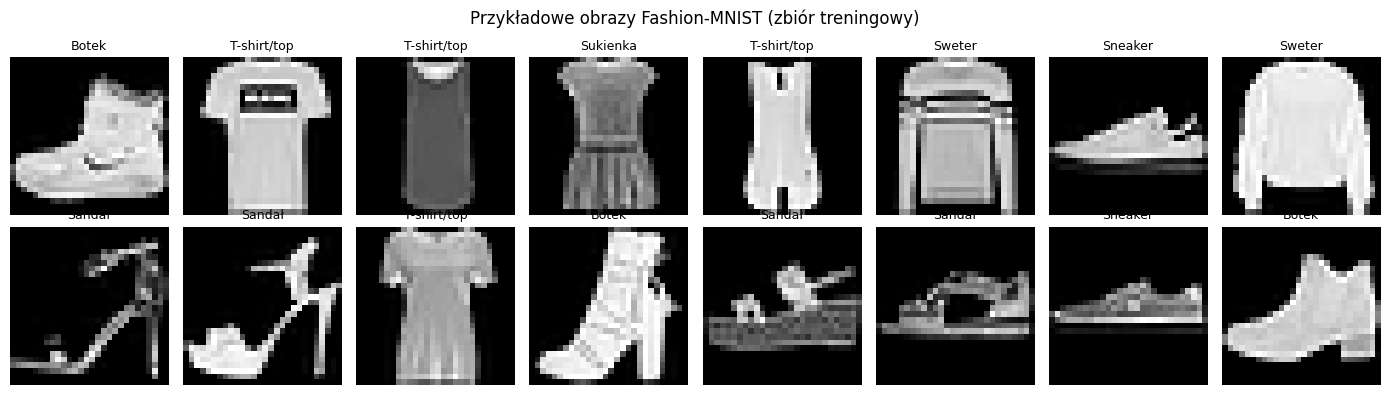

In [5]:
# Podgląd kilku obrazów z etykietami
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(NAZWY_KLAS[y_train[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("Przykładowe obrazy Fashion-MNIST (zbiór treningowy)")
plt.tight_layout(); plt.show()

### Softmax i entropia krzyżowa

Ostatnia warstwa klasyfikatora na $K$ klas ma $K$ neuronów zwracających liczby rzeczywiste $z_1, \dots, z_K$ (tzw. **logity**). Funkcja **softmax** zamienia je na rozkład prawdopodobieństwa:

$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}, \qquad \sum_k p_k = 1.$$

Funkcja straty **kategorialnej entropii krzyżowej** dla jednej próbki z prawdziwą klasą $y$ to

$$L = -\log p_y.$$

Intuicja: jeśli model daje prawdziwej klasie prawdopodobieństwo bliskie 1, strata jest bliska 0; jeśli bliskie 0, strata rośnie do nieskończoności - model jest mocno karany za pewne, ale błędne odpowiedzi.

### `sparse_categorical_crossentropy` vs `categorical_crossentropy`
- `categorical_crossentropy` - etykiety w postaci **one-hot**, np. klasa 3 -> `[0,0,0,1,0,0,0,0,0,0]`,
- `sparse_categorical_crossentropy` - etykiety jako **liczby całkowite** (0..9). Matematycznie to ta sama strata, ale nie trzeba tworzyć macierzy one-hot.

Nasze `y_train` to liczby całkowite, więc użyjemy wersji `sparse_`. **Typowy błąd:** użycie `categorical_crossentropy` z etykietami całkowitymi - Keras zgłosi błąd niezgodności kształtów.

### Ile parametrów ma warstwa gęsta? (W2)
Warstwa `Dense(n_out)` przy wejściu o wymiarze $n_{in}$ ma $n_{in} \cdot n_{out} + n_{out}$ parametrów (wagi + biasy). Dla `Flatten` 28x28 = 784 wejść i 128 neuronów: $784 \cdot 128 + 128 = 100\,480$.

In [6]:
# Model demonstracyjny: najprostszy MLP z jedną warstwą ukrytą
model_mlp = keras.Sequential([
    keras.Input(shape=(28, 28)),            # deklaracja kształtu wejścia (bez wymiaru batcha)
    layers.Flatten(),                       # 28x28 -> wektor 784
    layers.Dense(128, activation="relu"),   # warstwa ukryta
    layers.Dense(10, activation="softmax"), # 10 klas -> rozkład prawdopodobieństwa
], name="mlp_demo")

model_mlp.summary()   # sprawdź: 100 480 + 1 290 = 101 770 parametrów

Model: "mlp_demo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### `compile` i `fit`

- `compile(optimizer, loss, metrics)` - konfiguruje trening: czym optymalizujemy, co minimalizujemy i co dodatkowo raportujemy.
- `fit(x, y, epochs, batch_size, validation_data)` - właściwy trening. W każdej epoce model przechodzi raz przez cały zbiór treningowy w porcjach (mini-batchach) po `batch_size` próbek. Po każdej epoce liczone są metryki na zbiorze walidacyjnym.
- `evaluate(x, y)` - liczy stratę i metryki na podanym zbiorze, bez uczenia.

Epoch 1/10
391/391 - 6s - 16ms/step - accuracy: 0.8046 - loss: 0.5727 - val_accuracy: 0.8324 - val_loss: 0.4694
Epoch 2/10
391/391 - 1s - 3ms/step - accuracy: 0.8525 - loss: 0.4164 - val_accuracy: 0.8604 - val_loss: 0.4050
Epoch 3/10
391/391 - 2s - 4ms/step - accuracy: 0.8673 - loss: 0.3761 - val_accuracy: 0.8692 - val_loss: 0.3778
Epoch 4/10
391/391 - 2s - 4ms/step - accuracy: 0.8757 - loss: 0.3488 - val_accuracy: 0.8738 - val_loss: 0.3638
Epoch 5/10
391/391 - 2s - 4ms/step - accuracy: 0.8828 - loss: 0.3274 - val_accuracy: 0.8785 - val_loss: 0.3534
Epoch 6/10
391/391 - 1s - 3ms/step - accuracy: 0.8882 - loss: 0.3111 - val_accuracy: 0.8803 - val_loss: 0.3467
Epoch 7/10
391/391 - 1s - 3ms/step - accuracy: 0.8929 - loss: 0.2968 - val_accuracy: 0.8811 - val_loss: 0.3439
Epoch 8/10
391/391 - 1s - 3ms/step - accuracy: 0.8975 - loss: 0.2838 - val_accuracy: 0.8811 - val_loss: 0.3428
Epoch 9/10
391/391 - 1s - 3ms/step - accuracy: 0.9009 - loss: 0.2732 - val_accuracy: 0.8818 - val_loss: 0.3422


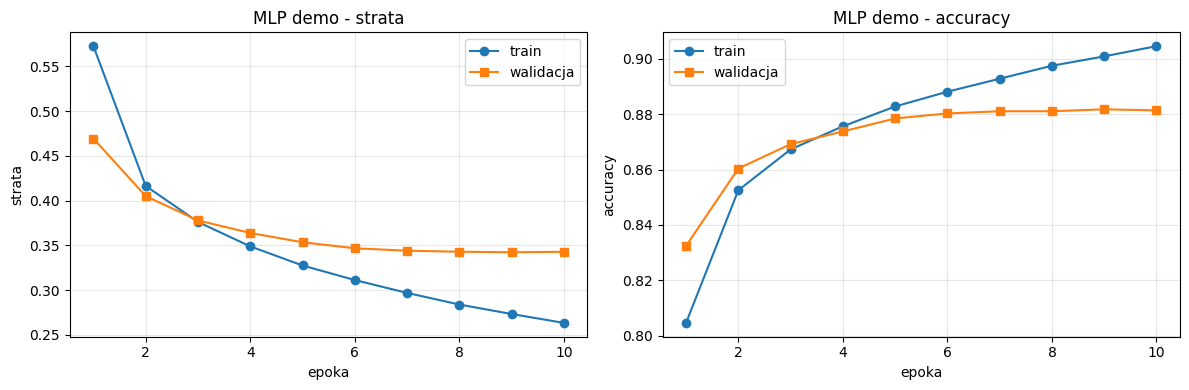

In [7]:
EPOKI_DEMO = 2 if SZYBKI_TRYB else 10

model_mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

t0 = time.time()
hist_demo = model_mlp.fit(
    x_train, y_train,
    epochs=EPOKI_DEMO,
    batch_size=128,
    validation_data=(x_val, y_val),   # walidacja liczona po każdej epoce
    verbose=2,                        # jedna linia na epokę
)
print(f"czas treningu: {time.time() - t0:.1f} s")
rysuj_historie(hist_demo, tytul="MLP demo")

### Jak czytać krzywe uczenia (W3)?

| Obserwacja | Diagnoza | Co zrobić |
|---|---|---|
| strata train i val wysokie, zbliżone | **niedouczenie** (underfitting) | większy model, dłuższy trening, większy lr |
| strata train maleje, val maleje i stabilizuje się | dobre dopasowanie | ewentualnie zatrzymać w minimum val |
| strata train maleje, val zaczyna **rosnąć** | **przeuczenie** (overfitting) | regularyzacja, więcej danych, early stopping |
| strata skacze / rośnie od początku | za duży learning rate, błąd w danych | zmniejszyć lr, sprawdzić dane |

Uwaga: w pierwszych epokach dokładność walidacyjna bywa **wyższa** niż treningowa. To nie błąd - metryki treningowe są uśredniane w trakcie epoki (model na początku epoki był gorszy), a walidacyjne liczone na końcu epoki.

### Zadanie 1.1 - Głębszy MLP

Zbuduj model `model_mlp` (Sequential) o architekturze:
`Input(28,28) -> Flatten -> Dense(256, relu) -> Dense(128, relu) -> Dense(10, softmax)`.

1. Skompiluj go z optymalizatorem Adam (lr = 1e-3), stratą `sparse_categorical_crossentropy` i metryką `accuracy`.
2. Wytrenuj przez `EPOKI_11` epok z `batch_size=128`, z walidacją na `(x_val, y_val)`. Historię zapisz w `hist_mlp`.
3. Narysuj krzywe uczenia funkcją `rysuj_historie`.
4. Oceń model na zbiorze **testowym** (`evaluate`) i wypisz dokładność.
5. Ręcznie policz liczbę parametrów i porównaj z `model_mlp.count_params()`.

**Kryteria sukcesu (pełny tryb, GPU):** dokładność walidacyjna >= 0.87, testowa >= 0.86; liczba parametrów zgadza się z Twoim rachunkiem.

**Wskazówki:** wzorem jest `model_mlp` powyżej. Parametry: $784\cdot256+256$, $256\cdot128+128$, $128\cdot10+10$.

In [33]:
EPOKI_11 = 2 if SZYBKI_TRYB else 15

# TODO: uzupełnij - zbuduj, skompiluj i wytrenuj model_mlp; zapisz historię w hist_mlp
model_mlp = keras.Sequential([
    keras.Input(shape=(28, 28)),            # deklaracja kształtu wejścia (bez wymiaru batcha)
    layers.Flatten(),                       # 28x28 -> wektor 784
    layers.Dense(256, activation="relu"),   # warstwa ukryta
    layers.Dense(128, activation="relu"),   # warstwa ukryta
    layers.Dense(10, activation="softmax"), # 10 klas -> rozkład prawdopodobieństwa
], name="model_mlp")

model_mlp.summary()

Model: "model_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_8 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
391/391 - 4s - 10ms/step - accuracy: 0.8158 - loss: 0.5226 - val_accuracy: 0.8551 - val_loss: 0.4182
Epoch 2/15
391/391 - 1s - 3ms/step - accuracy: 0.8647 - loss: 0.3749 - val_accuracy: 0.8628 - val_loss: 0.3891
Epoch 3/15
391/391 - 2s - 4ms/step - accuracy: 0.8767 - loss: 0.3354 - val_accuracy: 0.8727 - val_loss: 0.3642
Epoch 4/15
391/391 - 2s - 6ms/step - accuracy: 0.8861 - loss: 0.3098 - val_accuracy: 0.8724 - val_loss: 0.3601
Epoch 5/15
391/391 - 1s - 4ms/step - accuracy: 0.8934 - loss: 0.2895 - val_accuracy: 0.8736 - val_loss: 0.3523
Epoch 6/15
391/391 - 1s - 3ms/step - accuracy: 0.8998 - loss: 0.2708 - val_accuracy: 0.8773 - val_loss: 0.3449
Epoch 7/15
391/391 - 1s - 3ms/step - accuracy: 0.9052 - loss: 0.2563 - val_accuracy: 0.8821 - val_loss: 0.3351
Epoch 8/15
391/391 - 1s - 3ms/step - accuracy: 0.9090 - loss: 0.2443 - val_accuracy: 0.8809 - val_loss: 0.3372
Epoch 9/15
391/391 - 1s - 3ms/step - accuracy: 0.9138 - loss: 0.2318 - val_accuracy: 0.8788 - val_loss: 0.3535


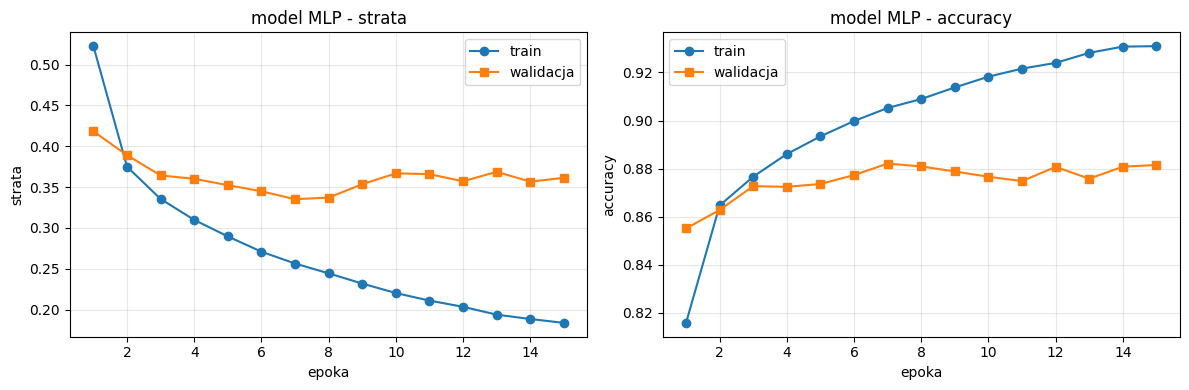

In [34]:
EPOKI_11 = 2 if SZYBKI_TRYB else 15

# Tworzymy świeży model od nowa, aby pozbyć się uszkodzonych wag z wartościami NaN
keras.utils.set_random_seed(SEED)
model_mlp = keras.Sequential([
    keras.Input(shape=(28, 28)),            # wejście 28x28
    layers.Flatten(),                       # spłaszczenie do 784
    layers.Dense(256, activation="relu"),   # warstwa ukryta 1
    layers.Dense(128, activation="relu"),   # warstwa ukryta 2
    layers.Dense(10, activation="softmax"), # 10 klas wyjściowych
], name="model_mlp")

model_mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

t0 = time.time()
hist_mlp = model_mlp.fit(
    x_train, y_train,
    epochs=EPOKI_11,
    batch_size=128,
    validation_data=(x_val, y_val),
    verbose=2,
)
print(f"czas treningu: {time.time() - t0:.1f} s")
rysuj_historie(hist_mlp, tytul="model MLP")

### Gdzie model się myli? Macierz pomyłek

Sama dokładność to za mało - chcemy wiedzieć, **które klasy** są mylone. Macierz pomyłek $C$ ma w komórce $C_{ij}$ liczbę próbek o prawdziwej klasie $i$, które model przypisał do klasy $j$. Na przekątnej są poprawne odpowiedzi. (Pełna analiza metryk klasyfikacji: W4 i L5.)

`model.predict(x)` zwraca macierz prawdopodobieństw o kształcie `(n, 10)`; klasę przewidywaną wybieramy przez `argmax` po osi 1.

suma prawdopodobieństw w 1. wierszu: 1.0


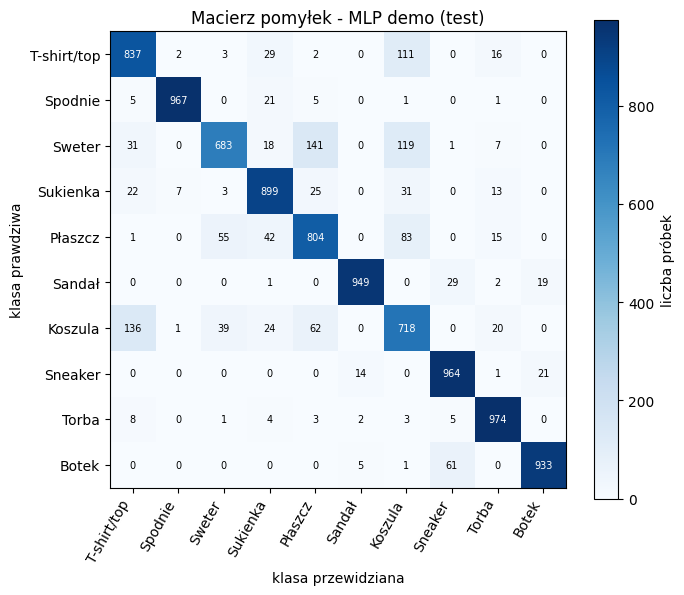

In [9]:
# Demonstracja na model_mlp: predykcja i macierz pomyłek
proby = model_mlp.predict(x_test, verbose=0)     # (n, 10) prawdopodobieństwa
y_pred_demo = proby.argmax(axis=1)                # klasa o największym prawdopodobieństwie
print("suma prawdopodobieństw w 1. wierszu:", proby[0].sum().round(4))  # softmax -> 1.0

cm = confusion_matrix(y_test, y_pred_demo, labels=range(10))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(NAZWY_KLAS, rotation=60, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(NAZWY_KLAS)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("klasa przewidziana"); ax.set_ylabel("klasa prawdziwa")
ax.set_title("Macierz pomyłek - MLP demo (test)")
plt.colorbar(im, ax=ax, label="liczba próbek"); plt.tight_layout(); plt.show()

### Zadanie 1.2 - Analiza błędów

Dla modelu `model_mlp` z zadania 1.1:

1. Wyznacz predykcje na zbiorze testowym (`y_pred_mlp`).
2. Policz **dokładność dla każdej klasy osobno** (odsetek poprawnych odpowiedzi wśród próbek danej klasy) i przedstaw ją na wykresie słupkowym z nazwami klas.
3. Znajdź **parę klas najczęściej mylonych** (największy element macierzy pomyłek poza przekątną) i wypisz ją.
4. Pokaż 10 błędnie sklasyfikowanych obrazów z podpisem "prawda / predykcja (prawdopodobieństwo)".

**Kryteria sukcesu:** wykres ma tytuł i opisane osie; potrafisz wyjaśnić, dlaczego właśnie te klasy są mylone.

**Wskazówki:** dokładność klasy $k$ to `cm[k, k] / cm[k].sum()`. Żeby znaleźć maksimum poza przekątną, skopiuj macierz i wyzeruj przekątną (`np.fill_diagonal`), potem `np.unravel_index(m.argmax(), m.shape)`.

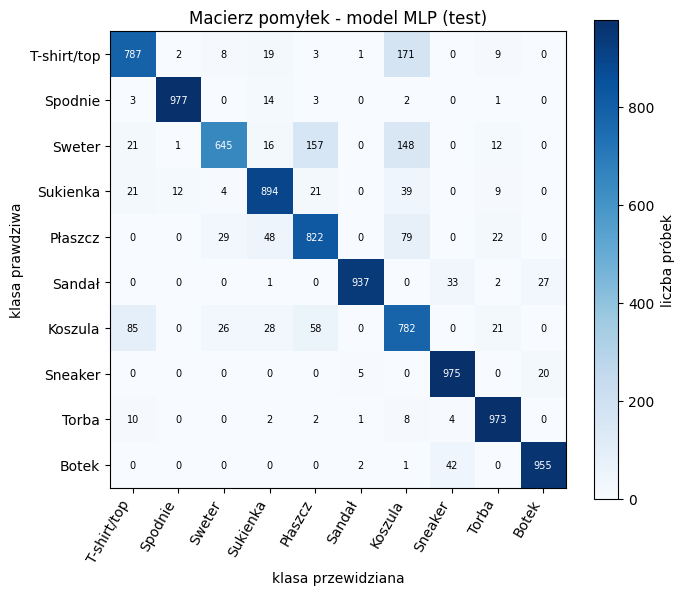

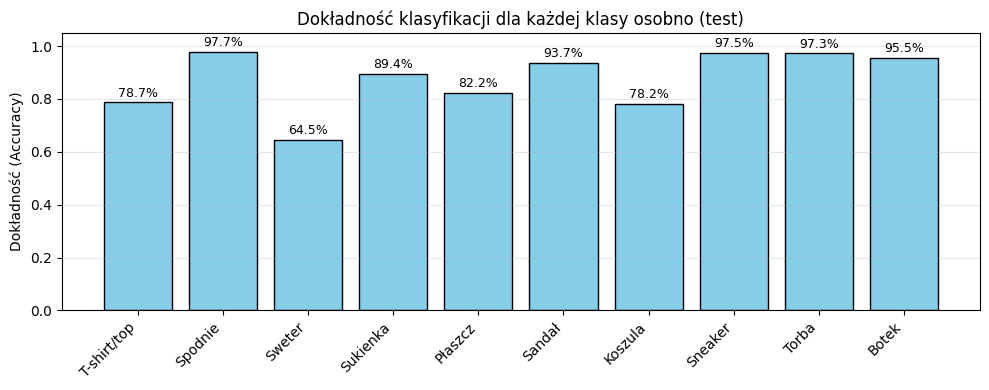

Najczęściej mylona para klas: Prawdziwa to [T-shirt/top], a model przewidział [Koszula] (pomylone 171 razy).


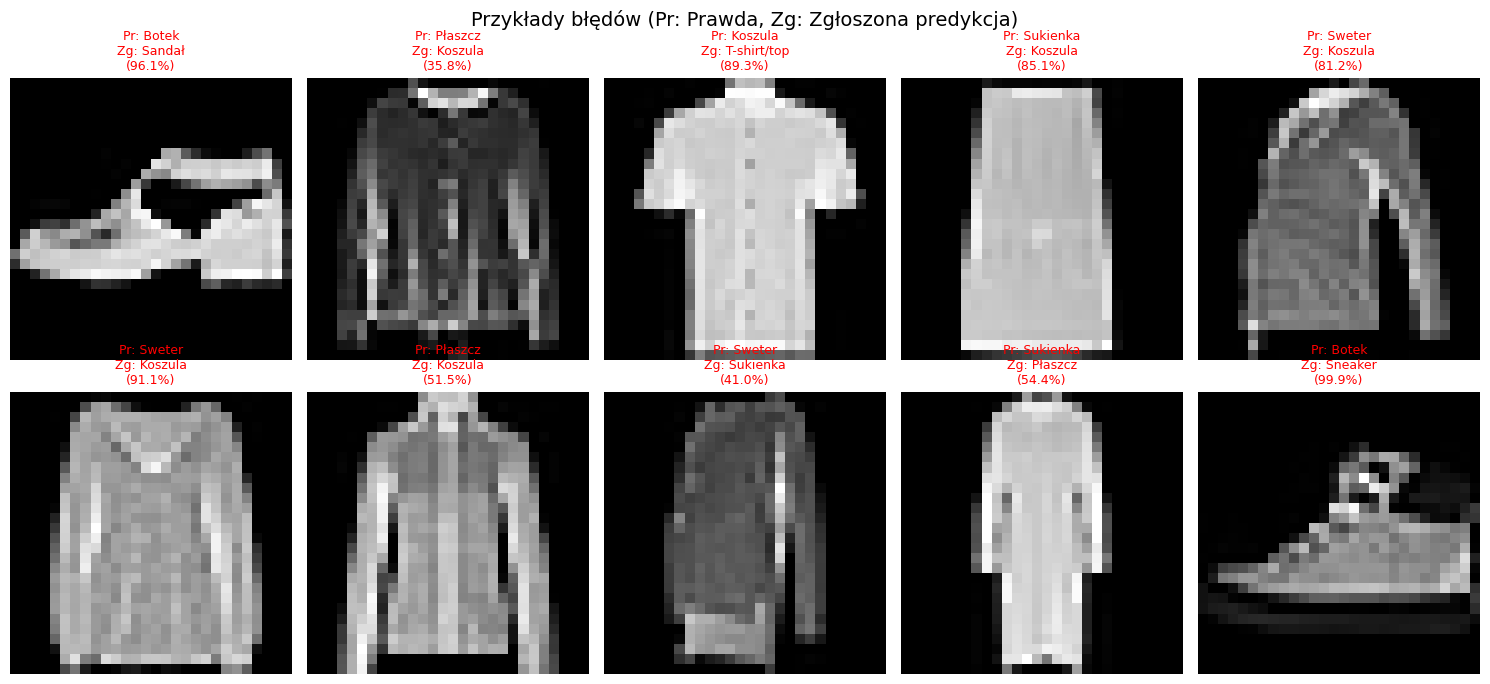

In [46]:
# 1. Generowanie predykcji (prawdopodobieństw i klas)
proby = model_mlp.predict(x_test, verbose=0)
y_pred_mlp = proby.argmax(axis=1)

# 2. Wykres 1: Macierz pomyłek (Twoja dotychczasowa wizualizacja)
cm = confusion_matrix(y_test, y_pred_mlp, labels=range(10))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(NAZWY_KLAS, rotation=60, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(NAZWY_KLAS)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("klasa przewidziana"); ax.set_ylabel("klasa prawdziwa")
ax.set_title("Macierz pomyłek - model MLP (test)")
plt.colorbar(im, ax=ax, label="liczba próbek"); plt.tight_layout(); plt.show()

# 3. Wykres 2: Dokładność dla każdej klasy osobno
dokladnosci_klas = []
for i in range(10):
    acc = cm[i, i] / cm[i].sum()
    dokladnosci_klas.append(acc)

plt.figure(figsize=(10, 4))
plt.bar(NAZWY_KLAS, dokladnosci_klas, color="skyblue", edgecolor="black")
plt.ylabel("Dokładność (Accuracy)")
plt.title("Dokładność klasyfikacji dla każdej klasy osobno (test)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.ylim(0, 1.05)
# Dodanie wartości procentowych nad słupkami
for idx, val in enumerate(dokladnosci_klas):
    plt.text(idx, val + 0.01, f"{val:.1%}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

# 4. Znajdź parę klas najczęściej mylonych
cm_bez_przekatnej = cm.copy()
np.fill_diagonal(cm_bez_przekatnej, 0)  # zerujemy poprawnie sklasyfikowane
prawdziwa_idx, przewidziana_idx = np.unravel_index(cm_bez_przekatnej.argmax(), cm_bez_przekatnej.shape)
najwiekszy_blad = cm_bez_przekatnej[prawdziwa_idx, przewidziana_idx]

print(f"Najczęściej mylona para klas: Prawdziwa to [{NAZWY_KLAS[prawdziwa_idx]}], "
      f"a model przewidział [{NAZWY_KLAS[przewidziana_idx]}] (pomylone {najwiekszy_blad} razy).")


# 5. Wyświetlenie 10 błędnie sklasyfikowanych obrazów
indeksy_bledow = np.where(y_pred_mlp != y_test)[0]
# Wybierzmy 10 pierwszych z brzegu błędów
wybrane_indeksy = indeksy_bledow[:10]

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for idx, ax in zip(wybrane_indeksy, axes.flat):
    ax.imshow(x_test[idx], cmap="gray")
    prawda_nazwa = NAZWY_KLAS[y_test[idx]]
    pred_nazwa = NAZWY_KLAS[y_pred_mlp[idx]]
    pewnosc = proby[idx, y_pred_mlp[idx]]  # prawdopodobieństwo dla przewidzianej klasy

    ax.set_title(f"Pr: {prawda_nazwa}\nZg: {pred_nazwa}\n({pewnosc:.1%})", fontsize=9,
                 color="red")
    ax.axis("off")
plt.suptitle("Przykłady błędów (Pr: Prawda, Zg: Zgłoszona predykcja)", fontsize=14, y=0.98)
plt.tight_layout(); plt.show()

## 2. Regresja: California Housing

### Zbiór danych
Dane ze spisu powszechnego w Kalifornii (1990): 20 640 dzielnic, 8 cech numerycznych (mediana dochodu, wiek budynków, średnia liczba pokoi, populacja, położenie geograficzne...). Cel: **mediana wartości domu** w dzielnicy, w setkach tysięcy dolarów.

### Co zmienia się względem klasyfikacji?
- warstwa wyjściowa: **1 neuron bez aktywacji** (aktywacja liniowa) - wyjście może być dowolną liczbą rzeczywistą,
- funkcja straty: **MSE** $= \frac{1}{n}\sum_i (y_i - \hat y_i)^2$ lub **MAE** $= \frac{1}{n}\sum_i |y_i - \hat y_i|$ (W3),
- metryki: MAE (w jednostkach celu, łatwa interpretacja), RMSE $= \sqrt{\text{MSE}}$, ewentualnie $R^2$.

MSE silniej karze duże błędy (kwadrat), MAE jest bardziej odporne na wartości odstające. Często trenujemy na MSE (gładki gradient), a raportujemy MAE.

In [11]:
dane = fetch_california_housing(as_frame=True)
df = dane.frame
if SZYBKI_TRYB:
    df = df.iloc[:2000]
print(df.shape)
df.describe().T.round(2)

(20640, 9)


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


### Standaryzacja - tylko na zbiorze treningowym!

Cechy mają bardzo różne skale (populacja - tysiące, mediana dochodu - kilka jednostek). Gradient względem wag przy cechach o dużej skali byłby ogromny, a przy małej - znikomy; trening byłby niestabilny. Dlatego standaryzujemy:

$$x' = \frac{x - \mu_{train}}{\sigma_{train}}.$$

**Kluczowe:** średnią $\mu$ i odchylenie $\sigma$ liczymy **wyłącznie na zbiorze treningowym**, a potem tymi samymi wartościami przekształcamy walidację i test. Gdybyśmy dopasowali `StandardScaler` do całych danych, informacja ze zbioru testowego "przeciekłaby" do treningu (**data leakage**, W4) - wynik testowy byłby zbyt optymistyczny. W praktyce produkcyjnej nowe dane też przekształcamy parametrami z treningu, bo przyszłości nie znamy.

Schemat: `scaler.fit(X_train)` -> `scaler.transform(X_train / X_val / X_test)`.

In [12]:
X = df[dane.feature_names].values.astype("float32")
y = df["MedHouseVal"].values.astype("float32")

# Podział 60 / 20 / 20: najpierw odcinamy test, potem z reszty walidację
X_tmp, X_te_r, y_tmp, y_te_r = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_tr_r, X_va_r, y_tr_r, y_va_r = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=SEED)

scaler = StandardScaler().fit(X_tr_r)       # fit TYLKO na train
X_tr_s = scaler.transform(X_tr_r)           # transform na wszystkich podzbiorach
X_va_s = scaler.transform(X_va_r)
X_te_s = scaler.transform(X_te_r)

print("train/val/test:", X_tr_s.shape, X_va_s.shape, X_te_s.shape)
print("średnie cech po standaryzacji (train):", X_tr_s.mean(axis=0).round(3))
print("średnie cech po standaryzacji (test): ", X_te_s.mean(axis=0).round(3), "<- nie muszą być 0")

train/val/test: (12384, 8) (4128, 8) (4128, 8)
średnie cech po standaryzacji (train): [ 0.  0. -0.  0. -0.  0.  0.  0.]
średnie cech po standaryzacji (test):  [-0.021  0.014 -0.004  0.011 -0.005 -0.01  -0.026  0.03 ] <- nie muszą być 0


### Baseline - zawsze zaczynaj od punktu odniesienia

Zanim powiesz, że sieć "działa dobrze", porównaj ją z czymś prostym. Najprostszy baseline w regresji: **zawsze przewiduj średnią z treningu**. Jeśli sieć nie jest wyraźnie lepsza, coś jest nie tak (dane, skalowanie, architektura).

In [13]:
# Baseline 0: stała predykcja = średnia celu na zbiorze treningowym
pred_sr = np.full_like(y_te_r, y_tr_r.mean())
mae_sr = mean_absolute_error(y_te_r, pred_sr)
rmse_sr = np.sqrt(mean_squared_error(y_te_r, pred_sr))
print(f"Baseline (średnia): MAE = {mae_sr:.3f}, RMSE = {rmse_sr:.3f}  (jednostka: 100 tys. $)")

Baseline (średnia): MAE = 0.905, RMSE = 1.145  (jednostka: 100 tys. $)


### Zadanie 2.1 - Baseline liniowy

Mocniejszym punktem odniesienia jest **regresja liniowa** (klasyczny model ML, W1).

1. Dopasuj `LinearRegression` ze `sklearn` do `(X_tr_s, y_tr_r)`.
2. Policz MAE i RMSE na zbiorze **testowym**; zapisz w zmiennych `mae_lin`, `rmse_lin`.
3. Wypisz porównanie z baseline'em średniej.

**Kryteria sukcesu (pełny tryb):** MAE regresji liniowej ok. 0.53, wyraźnie mniej niż baseline średniej (ok. 0.9).

In [45]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

model_lin = LinearRegression()
model_lin.fit(X_tr_s, y_tr_r)

pred_lin = model_lin.predict(X_te_s)

mae_lin = mean_absolute_error(y_te_r, pred_lin)
rmse_lin = np.sqrt(mean_squared_error(y_te_r, pred_lin))


print(f"LinearRegression (Test): MAE = {mae_lin:.3f}, RMSE = {rmse_lin:.3f}")


LinearRegression (Test): MAE = 0.533, RMSE = 0.750


### Zadanie 2.2 - Sieć do regresji

1. Zbuduj `model_reg`: `Input(8) -> Dense(64, relu) -> Dense(64, relu) -> Dense(1)` (bez aktywacji na wyjściu!).
2. Skompiluj z Adam (lr = 1e-3), stratą `"mse"` i metryką `"mae"`.
3. Wytrenuj `EPOKI_22` epok, `batch_size=64`, z walidacją `(X_va_s, y_va_r)`. Narysuj krzywe (`metryka="mae"`).
4. Policz MAE i RMSE na teście (`mae_nn`, `rmse_nn`) i zestaw w tabeli (pandas DataFrame) z baseline'ami.
5. Narysuj wykres rozrzutu: wartości prawdziwe vs przewidziane na teście, z linią $y = x$.

**Kryteria sukcesu (pełny tryb):** MAE sieci < 0.42 (wyraźnie lepiej niż liniowa).

**Wskazówki:** `model_reg.predict(X_te_s).ravel()` - wyjście ma kształt `(n, 1)`, spłaszczamy je do `(n,)`. Zapomnienie o `ravel()` przy liczeniu `y - y_pred` daje broadcasting do macierzy `(n, n)` - klasyczny, cichy błąd!

Epoch 1/60
194/194 - 4s - 20ms/step - loss: 1.3029 - mae: 0.7650 - val_loss: 0.6043 - val_mae: 0.5215
Epoch 2/60
194/194 - 1s - 3ms/step - loss: 0.4486 - mae: 0.4729 - val_loss: 0.4057 - val_mae: 0.4486
Epoch 3/60
194/194 - 1s - 3ms/step - loss: 0.3861 - mae: 0.4409 - val_loss: 0.3758 - val_mae: 0.4345
Epoch 4/60
194/194 - 1s - 4ms/step - loss: 0.3679 - mae: 0.4300 - val_loss: 0.3642 - val_mae: 0.4285
Epoch 5/60
194/194 - 1s - 3ms/step - loss: 0.3566 - mae: 0.4222 - val_loss: 0.3588 - val_mae: 0.4252
Epoch 6/60
194/194 - 1s - 3ms/step - loss: 0.3492 - mae: 0.4160 - val_loss: 0.3699 - val_mae: 0.4236
Epoch 7/60
194/194 - 1s - 3ms/step - loss: 0.3435 - mae: 0.4106 - val_loss: 0.3612 - val_mae: 0.4200
Epoch 8/60
194/194 - 1s - 3ms/step - loss: 0.3362 - mae: 0.4053 - val_loss: 0.3639 - val_mae: 0.4167
Epoch 9/60
194/194 - 1s - 3ms/step - loss: 0.3323 - mae: 0.4011 - val_loss: 0.3792 - val_mae: 0.4132
Epoch 10/60
194/194 - 1s - 3ms/step - loss: 0.3264 - mae: 0.3971 - val_loss: 0.3421 - val_

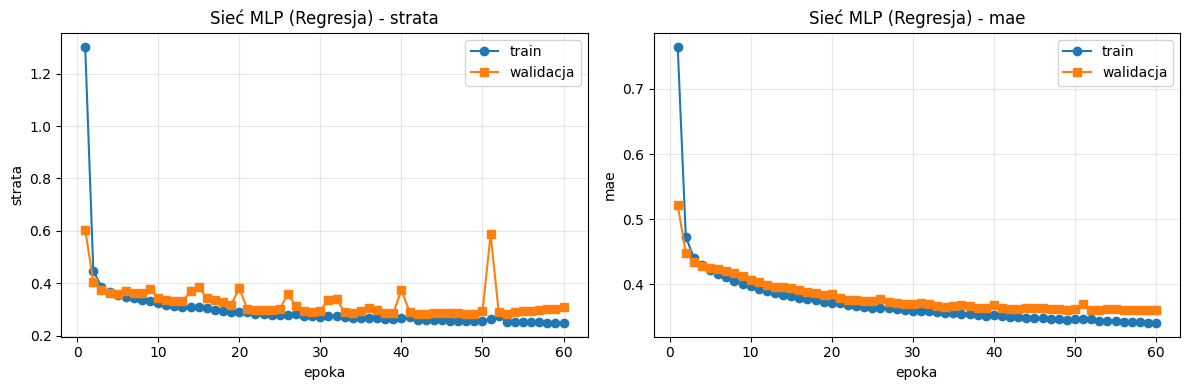


PODSUMOWANIE METRYK (CALIFORNIA HOUSING)
             Model  MAE (Test)  RMSE (Test)
Baseline (Średnia)    0.905296     1.144806
  Regresja Liniowa    0.533302     0.749527
Sieć MLP (Zad 2.2)    0.360006     0.532912


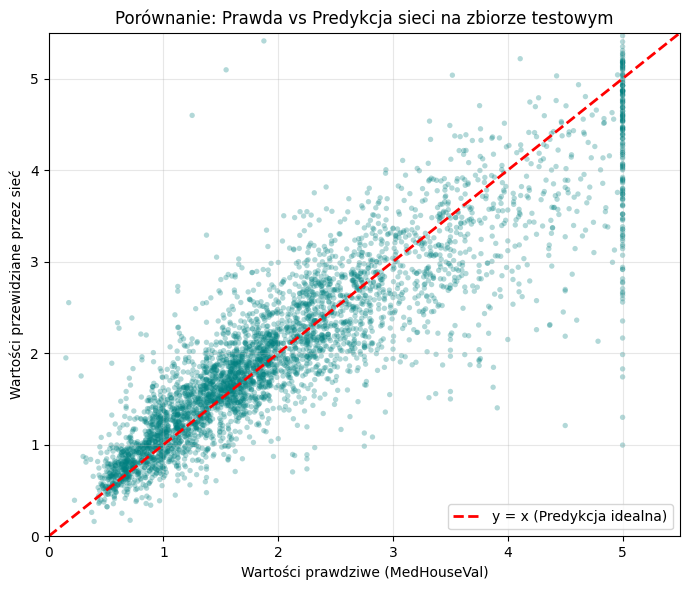

In [47]:
EPOKI_22 = 3 if SZYBKI_TRYB else 60

keras.utils.set_random_seed(SEED)
model_reg = keras.Sequential([
    keras.Input(shape=(8,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1) # Wyjście ciągłe (liniowe)
], name="model_reg")

model_reg.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)

# Trening
t0 = time.time()
hist_reg = model_reg.fit(
    X_tr_s, y_tr_r,
    epochs=EPOKI_22,
    batch_size=64,
    validation_data=(X_va_s, y_va_r),
    verbose=2
)
print(f"Czas treningu sieci: {time.time() - t0:.1f} s")

# Rysowanie krzywych uczenia (MAE)
rysuj_historie(hist_reg, metryka="mae", tytul="Sieć MLP (Regresja)")

# Predykcja i ewaluacja na teście
pred_nn = model_reg.predict(X_te_s, verbose=0).ravel()
mae_nn = mean_absolute_error(y_te_r, pred_nn)
rmse_nn = np.sqrt(mean_squared_error(y_te_r, pred_nn))

# Zestawienie wyników w tabeli
wyniki_df = pd.DataFrame({
    "Model": ["Baseline (Średnia)", "Regresja Liniowa", "Sieć MLP (Zad 2.2)"],
    "MAE (Test)": [mae_sr, mae_lin, mae_nn],
    "RMSE (Test)": [rmse_sr, rmse_lin, rmse_nn]
})

print("\n" + "="*60)
print("PODSUMOWANIE METRYK (CALIFORNIA HOUSING)")
print("="*60)
print(wyniki_df.to_string(index=False))
print("="*60)

# Wykres rozrzutu: wartości prawdziwe vs przewidziane
plt.figure(figsize=(7, 6))
plt.scatter(y_te_r, pred_nn, alpha=0.3, color="teal", edgecolor="none", s=15)
# Linia idealnej predykcji y = x
lims = [0, 5.5]
plt.plot(lims, lims, color="red", linestyle="--", linewidth=2, label="y = x (Predykcja idealna)")
plt.xlabel("Wartości prawdziwe (MedHouseVal)")
plt.ylabel("Wartości przewidziane przez sieć")
plt.title("Porównanie: Prawda vs Predykcja sieci na zbiorze testowym")
plt.xlim(lims)
plt.ylim(lims)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Callbacki - automatyzacja treningu

**Callback** to obiekt, którego metody Keras wywołuje w określonych momentach treningu (początek/koniec epoki, batcha, treningu). Najważniejsze wbudowane:

| Callback | Co robi | Kluczowe argumenty |
|---|---|---|
| `EarlyStopping` | przerywa trening, gdy monitorowana metryka przestaje się poprawiać | `monitor="val_loss"`, `patience`, `restore_best_weights=True` |
| `ModelCheckpoint` | zapisuje model (lub wagi) na dysk, np. tylko gdy jest najlepszy | `filepath` (`.keras` lub `.weights.h5`), `save_best_only=True` |
| `ReduceLROnPlateau` | zmniejsza learning rate, gdy metryka stoi w miejscu | `factor` (np. 0.5), `patience`, `min_lr` |

**Early stopping jako regularyzacja (W3):** zatrzymując trening w minimum `val_loss`, nie pozwalamy sieci "zapamiętać" szumu ze zbioru treningowego. `patience` mówi, ile epok bez poprawy tolerujemy (krzywa walidacyjna jest zaszumiona, więc 1 epoka to za mało). `restore_best_weights=True` przywraca wagi z najlepszej epoki - bez tego zostałyby wagi z ostatniej (gorszej) epoki.

**ReduceLROnPlateau - intuicja:** na początku duży krok pozwala szybko zejść w dół funkcji straty; blisko minimum duży krok "przeskakuje" dolinę, więc krok zmniejszamy.

Epoch 11: early stopping
Restoring model weights from the end of the best epoch: 8.
Wykonano 11 z 50 epok; najlepsza epoka (min val_loss): 8


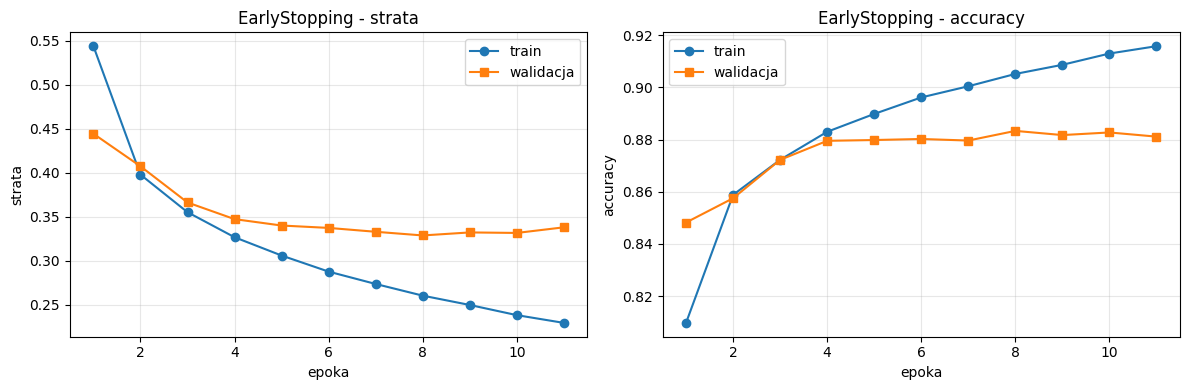

In [16]:
# Demonstracja: EarlyStopping na klasyfikacji Fashion-MNIST z dużą maksymalną liczbą epok
EPOKI_MAX_DEMO = 3 if SZYBKI_TRYB else 50

wczesne_zatrzymanie = keras.callbacks.EarlyStopping(
    monitor="val_loss",          # obserwujemy stratę walidacyjną
    patience=3,                  # 3 epoki bez poprawy -> stop
    restore_best_weights=True,   # przywróć wagi z najlepszej epoki
    verbose=1,
)

model_es = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten(),
                             layers.Dense(256, activation="relu"),
                             layers.Dense(10, activation="softmax")])
model_es.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_es = model_es.fit(x_train, y_train, epochs=EPOKI_MAX_DEMO, batch_size=128,
                       validation_data=(x_val, y_val), callbacks=[wczesne_zatrzymanie], verbose=0)

n_epok = len(hist_es.history["loss"])
najlepsza = int(np.argmin(hist_es.history["val_loss"])) + 1
print(f"Wykonano {n_epok} z {EPOKI_MAX_DEMO} epok; najlepsza epoka (min val_loss): {najlepsza}")
rysuj_historie(hist_es, tytul="EarlyStopping")

### Zadanie 3.1 - Trzy callbacki naraz (regresja)

Wytrenuj **nowy** model o architekturze jak w zad. 2.2 (`model_cb`) na danych California Housing, z maksymalną liczbą epok `EPOKI_MAX_31` i trzema callbackami:

- `EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)`,
- `ModelCheckpoint("najlepszy_reg.keras", monitor="val_loss", save_best_only=True)`,
- `ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)`.

Następnie:
1. wypisz, po ilu epokach trening się zatrzymał i która epoka była najlepsza,
2. narysuj, jak zmieniał się learning rate w kolejnych epokach (Keras zapisuje go w `historia.history["learning_rate"]`),
3. wczytaj model z pliku `najlepszy_reg.keras` i policz jego MAE na teście.

**Kryteria sukcesu:** plik `najlepszy_reg.keras` istnieje; w pełnym trybie trening kończy się przed limitem epok, a lr zmalał co najmniej raz; MAE testowe wczytanego modelu <= MAE z zadania 2.2 (lub bardzo zbliżone).

**Wskazówka:** callbacki przekazujemy jako listę: `fit(..., callbacks=[cb1, cb2, cb3])`.

Epoch 1/200

Epoch 1: val_loss improved from None to 0.60430, saving model to najlepszy_reg.keras

Epoch 1: finished saving model to najlepszy_reg.keras
194/194 - 3s - 14ms/step - loss: 1.3029 - mae: 0.7650 - val_loss: 0.6043 - val_mae: 0.5215 - learning_rate: 0.0010
Epoch 2/200

Epoch 2: val_loss improved from 0.60430 to 0.40568, saving model to najlepszy_reg.keras

Epoch 2: finished saving model to najlepszy_reg.keras
194/194 - 1s - 4ms/step - loss: 0.4486 - mae: 0.4729 - val_loss: 0.4057 - val_mae: 0.4486 - learning_rate: 0.0010
Epoch 3/200

Epoch 3: val_loss improved from 0.40568 to 0.37578, saving model to najlepszy_reg.keras

Epoch 3: finished saving model to najlepszy_reg.keras
194/194 - 1s - 4ms/step - loss: 0.3861 - mae: 0.4409 - val_loss: 0.3758 - val_mae: 0.4345 - learning_rate: 0.0010
Epoch 4/200

Epoch 4: val_loss improved from 0.37578 to 0.36421, saving model to najlepszy_reg.keras

Epoch 4: finished saving model to najlepszy_reg.keras
194/194 - 1s - 4ms/step - loss: 0.36

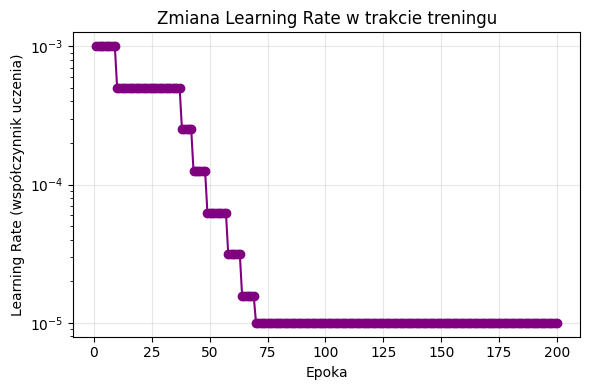


Wczytany model (najlepszy_reg.keras) na zbiorze testowym:
MAE = 0.366, RMSE = 0.541


In [48]:
EPOKI_MAX_31 = 3 if SZYBKI_TRYB else 200

# 1. Definicja callbacków
es = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

mcp = keras.callbacks.ModelCheckpoint(
    filepath="najlepszy_reg.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

rlr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-5,
    verbose=1
)

# 2. Inicjalizacja nowego, świeżego modelu o identycznej architekturze
keras.utils.set_random_seed(SEED)
model_cb = keras.Sequential([
    keras.Input(shape=(8,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1)
], name="model_cb")

model_cb.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)

# 3. Trening z listą callbacków
hist_cb = model_cb.fit(
    X_tr_s, y_tr_r,
    epochs=EPOKI_MAX_31,
    batch_size=64,
    validation_data=(X_va_s, y_va_r),
    callbacks=[es, mcp, rlr],
    verbose=2
)

# 4. Analiza zakończenia treningu
n_epok = len(hist_cb.history["loss"])
najlepsza_epoka = int(np.argmin(hist_cb.history["val_loss"])) + 1
print("\n" + "="*60)
print(f"Trening zatrzymał się po {n_epok} epokach.")
print(f"Najlepsza epoka (min val_loss): {najlepsza_epoka}")
print("="*60)

# 5. Wykres zmian learning rate
plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, n_epok + 1), hist_cb.history["learning_rate"], "o-", color="purple")
plt.xlabel("Epoka")
plt.ylabel("Learning Rate (współczynnik uczenia)")
plt.title("Zmiana Learning Rate w trakcie treningu")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Wczytanie zapisanego najlepszego modelu i ewaluacja
model_wczytany = keras.models.load_model("najlepszy_reg.keras")
pred_wczytany = model_wczytany.predict(X_te_s, verbose=0).ravel()

mae_cb = mean_absolute_error(y_te_r, pred_wczytany)
rmse_cb = np.sqrt(mean_squared_error(y_te_r, pred_wczytany))

print("\n" + "="*60)
print(f"Wczytany model (najlepszy_reg.keras) na zbiorze testowym:")
print(f"MAE = {mae_cb:.3f}, RMSE = {rmse_cb:.3f}")
print("="*60)

---
## Przerwa (10 min)
---

## 4. Optymalizatory i learning rate

Przypomnienie z W3 (wzory dla jednego parametru $w$, gradient $g_t = \nabla_w L$, learning rate $\eta$):

- **SGD:** $w \leftarrow w - \eta\, g_t$. Prosty, ale wolny w "wąskich dolinach" funkcji straty.
- **SGD z momentum:** $v \leftarrow \beta v - \eta g_t,\; w \leftarrow w + v$ (typowo $\beta = 0.9$). Jak kulka toczona po zboczu - "rozpęd" wygładza oscylacje i przyspiesza ruch w spójnym kierunku.
- **RMSprop:** $s \leftarrow \rho s + (1-\rho) g_t^2,\; w \leftarrow w - \frac{\eta}{\sqrt{s}+\epsilon} g_t$. Każdy parametr ma własny, adaptacyjny krok - duże gradienty są tłumione.
- **Adam:** łączy momentum (średnia gradientów $m$) i RMSprop (średnia kwadratów $v$) z korekcją obciążenia: $w \leftarrow w - \eta\,\frac{\hat m}{\sqrt{\hat v}+\epsilon}$. Bardzo dobry wybór domyślny (lr = 1e-3).

**Learning rate** to zwykle najważniejszy hiperparametr. Za mały - trening bardzo wolny; za duży - strata oscyluje lub rośnie (rozbieżność, jak w L1).

Do porównań użyjemy funkcji, która za każdym razem buduje **identyczny** model od nowa (te same seedy), zmieniając tylko optymalizator - wtedy porównanie jest uczciwe.

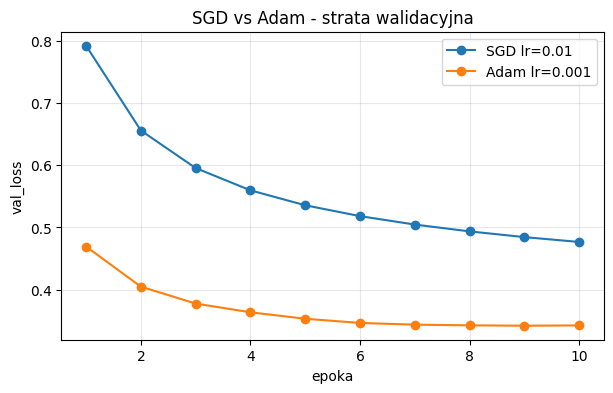

In [18]:
EPOKI_OPT = 2 if SZYBKI_TRYB else 10

def zbuduj_mlp_fashion():
    # Ten sam MLP za każdym razem; seed gwarantuje identyczną inicjalizację wag
    keras.utils.set_random_seed(SEED)
    return keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten(),
                             layers.Dense(128, activation="relu"),
                             layers.Dense(10, activation="softmax")])

def trenuj_z_optymalizatorem(optymalizator, epoki=EPOKI_OPT):
    # Trenuje świeży model z podanym optymalizatorem i zwraca słownik historii
    model = zbuduj_mlp_fashion()
    model.compile(optimizer=optymalizator, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = model.fit(x_train, y_train, epochs=epoki, batch_size=128,
                  validation_data=(x_val, y_val), verbose=0)
    return h.history

# Demonstracja: zwykły SGD vs Adam
wyniki_demo = {
    "SGD lr=0.01": trenuj_z_optymalizatorem(keras.optimizers.SGD(learning_rate=0.01)),
    "Adam lr=0.001": trenuj_z_optymalizatorem(keras.optimizers.Adam(learning_rate=0.001)),
}
plt.figure(figsize=(7, 4))
for nazwa, h in wyniki_demo.items():
    plt.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], "o-", label=nazwa)
plt.xlabel("epoka"); plt.ylabel("val_loss"); plt.title("SGD vs Adam - strata walidacyjna")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Zadanie 4.1 - Porównanie czterech optymalizatorów

Używając `trenuj_z_optymalizatorem`, porównaj:
- `SGD(learning_rate=0.01)`,
- `SGD(learning_rate=0.01, momentum=0.9)`,
- `RMSprop(learning_rate=0.001)`,
- `Adam(learning_rate=0.001)`.

1. Zapisz historie w słowniku `wyniki_opt` (klucz = nazwa).
2. Narysuj na **jednym** wykresie `val_loss` wszystkich wariantów, a na drugim `val_accuracy`.
3. Utwórz tabelę (DataFrame) z najlepszą `val_accuracy` i epoką, w której ją osiągnięto.

**Kryteria sukcesu:** SGD bez momentum powinien być wyraźnie najwolniejszy; potrafisz to wyjaśnić na podstawie wzorów powyżej.

**Uwaga:** optymalizator to obiekt ze stanem (np. bufor momentum) - dla każdego modelu twórz **nową** instancję, nie używaj tej samej dwa razy.

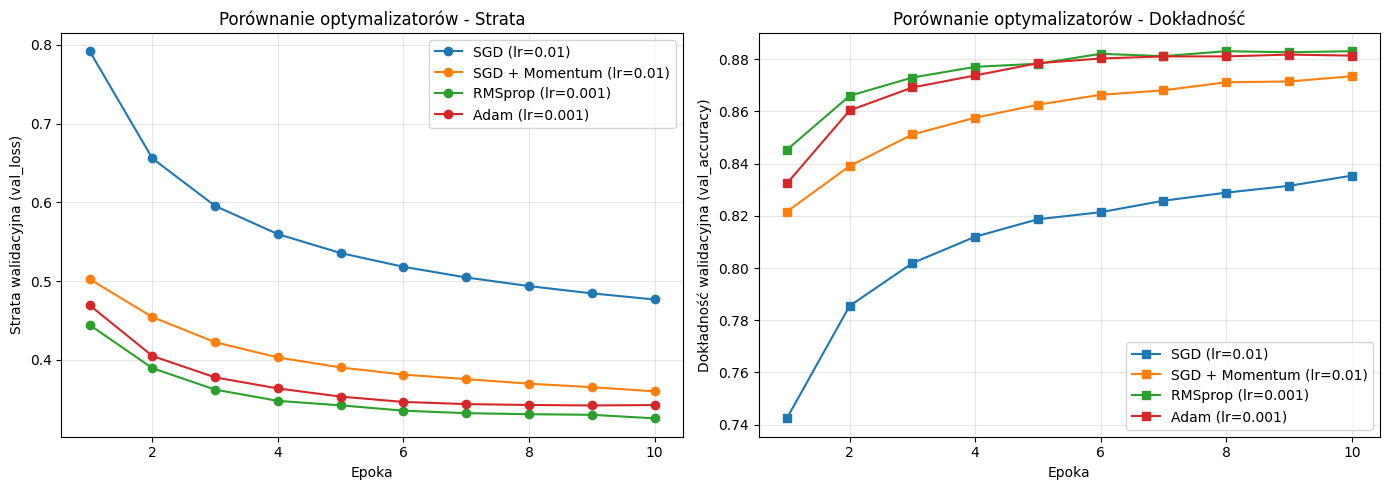

PORÓWNANIE OPTYMALIZATORÓW (FASHION-MNIST)
           Optymalizator  Max Val Accuracy  Najlepsza epoka
           SGD (lr=0.01)            0.8354               10
SGD + Momentum (lr=0.01)            0.8735               10
      RMSprop (lr=0.001)            0.8831                8
         Adam (lr=0.001)            0.8818                9


In [50]:
wyniki_opt = {
    "SGD (lr=0.01)": trenuj_z_optymalizatorem(keras.optimizers.SGD(learning_rate=0.01)),
    "SGD + Momentum (lr=0.01)": trenuj_z_optymalizatorem(keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)),
    "RMSprop (lr=0.001)": trenuj_z_optymalizatorem(keras.optimizers.RMSprop(learning_rate=0.001)),
    "Adam (lr=0.001)": trenuj_z_optymalizatorem(keras.optimizers.Adam(learning_rate=0.001))
}

# Wykresy porównawcze
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
epoki = np.arange(1, EPOKI_OPT + 1)

for nazwa, h in wyniki_opt.items():
    ax[0].plot(epoki, h["val_loss"], "o-", label=nazwa)
    ax[1].plot(epoki, h["val_accuracy"], "s-", label=nazwa)

ax[0].set_xlabel("Epoka")
ax[0].set_ylabel("Strata walidacyjna (val_loss)")
ax[0].set_title("Porównanie optymalizatorów - Strata")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].set_xlabel("Epoka")
ax[1].set_ylabel("Dokładność walidacyjna (val_accuracy)")
ax[1].set_title("Porównanie optymalizatorów - Dokładność")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Tabela podsumowująca
tabela_dane = []
for nazwa, h in wyniki_opt.items():
    najlepsza_dokladnosc = np.max(h["val_accuracy"])
    najlepsza_epoka_opt = np.argmax(h["val_accuracy"]) + 1
    tabela_dane.append({
        "Optymalizator": nazwa,
        "Max Val Accuracy": najlepsza_dokladnosc,
        "Najlepsza epoka": najlepsza_epoka_opt
    })

wyniki_opt_df = pd.DataFrame(tabela_dane)
print("PORÓWNANIE OPTYMALIZATORÓW (FASHION-MNIST)")
print(wyniki_opt_df.to_string(index=False))

### Zadanie 4.2 - Wpływ learning rate

Dla optymalizatora Adam sprawdź learning rate z listy `[1e-4, 1e-3, 1e-2, 1e-1]`.

1. Narysuj krzywe `loss` (treningowej!) dla wszystkich wartości na jednym wykresie.
2. Opisz w komórce markdown (2-3 zdania): który lr jest za mały, który za duży i po czym to widać.

**Kryteria sukcesu:** dla lr = 0.1 widać wyraźnie gorszą (wyższą, niestabilną) stratę, dla 1e-4 - powolny spadek.

**Wskazówka:** jeśli strata dla dużego lr robi się `nan`, to też jest wynik - zapisz to w wnioskach (rozbieżność).

Trenowanie: Adam z lr=0.0001...
Trenowanie: Adam z lr=0.001...
Trenowanie: Adam z lr=0.01...
Trenowanie: Adam z lr=0.1...


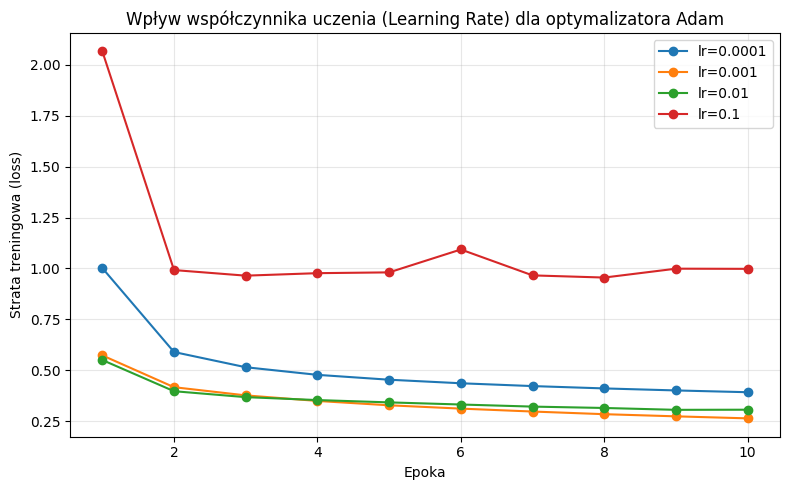

In [51]:
lista_lr = [1e-4, 1e-3, 1e-2, 1e-1]
wyniki_lr = {}

# Przeprowadzenie eksperymentu dla każdego learning rate
for lr in lista_lr:
    print(f"Trenowanie: Adam z lr={lr}...")
    opt = keras.optimizers.Adam(learning_rate=lr)
    historia = trenuj_z_optymalizatorem(opt)
    wyniki_lr[f"lr={lr}"] = historia["loss"]

# Wykres porównawczy straty treningowej
plt.figure(figsize=(8, 5))
epoki = np.arange(1, EPOKI_OPT + 1)

for klucz, strata in wyniki_lr.items():
    plt.plot(epoki, strata, "o-", label=klucz)

plt.xlabel("Epoka")
plt.ylabel("Strata treningowa (loss)")
plt.title("Wpływ współczynnika uczenia (Learning Rate) dla optymalizatora Adam")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Wnioski:

1. Za mały learning rate (`lr=1e-4`): Spadek straty treningowej jest bardzo powolny i stabilny. Model potrzebowałby znacznie większej liczby epok, aby zbliżyć się do optymalnego rozwiązania.
2. Optymalny learning rate (`lr=1e-3` lub `lr=1e-2`): Wartość `1e-3` (domyślna dla Adama) wykazuje szybką i stabilną zbieżność. Wartość `1e-2` również bardzo szybko minimalizuje stratę.
3. Za duży learning rate (`lr=1e-1`): Strata ulega gwałtownym oscylacjom, bardzo słabo spada, a w skrajnych przypadkach proces uczenia staje się całkowicie rozbieżny. Krok gradientu jest zbyt duży, przez co optymalizator "przemieszcza się" chaotycznie po powierzchni straty.

## 5. Celowe przeuczenie i jego "leczenie"

### Przeuczenie (overfitting)
Model o dużej pojemności (dużo parametrów) trenowany na małym zbiorze potrafi "zapamiętać" dane treningowe łącznie z szumem. Objaw: strata treningowa spada niemal do zera, a walidacyjna po pewnym czasie **rośnie**. Żeby wyraźnie to zobaczyć, celowo:
- zmniejszymy zbiór treningowy (do 1000 obrazów),
- użyjemy dużej sieci (3 x 512 neuronów, ok. 930 tys. parametrów),
- będziemy trenować długo.

### Metody regularyzacji (W2, W3)
- **Dropout($p$):** w trakcie treningu każdy neuron jest losowo "wyłączany" z prawdopodobieństwem $p$ (pozostałe są skalowane przez $1/(1-p)$). Sieć nie może polegać na pojedynczych neuronach - uczy się reprezentacji redundantnych. Działa jak uśrednianie wielu "podsieci". W predykcji Dropout jest wyłączony.
- **L2 (weight decay):** do straty dodajemy karę $\lambda \sum w^2$. Gradient kary $2\lambda w$ ściąga wagi w stronę zera - preferowane są "gładsze" funkcje. W Keras: `kernel_regularizer=keras.regularizers.l2(lambda)`.
- **BatchNormalization:** normalizuje aktywacje w mini-batchu do średniej 0 i wariancji 1, potem skaluje uczonymi parametrami $\gamma, \beta$:
  $\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}},\; y = \gamma \hat{x} + \beta$.
  Głównie **stabilizuje i przyspiesza** trening (pozwala na większy lr); efekt regularyzujący jest uboczny (szum statystyk batcha) i słabszy niż Dropout.
- **Early stopping** - poznaliśmy w sekcji 3.

parametry: 932362


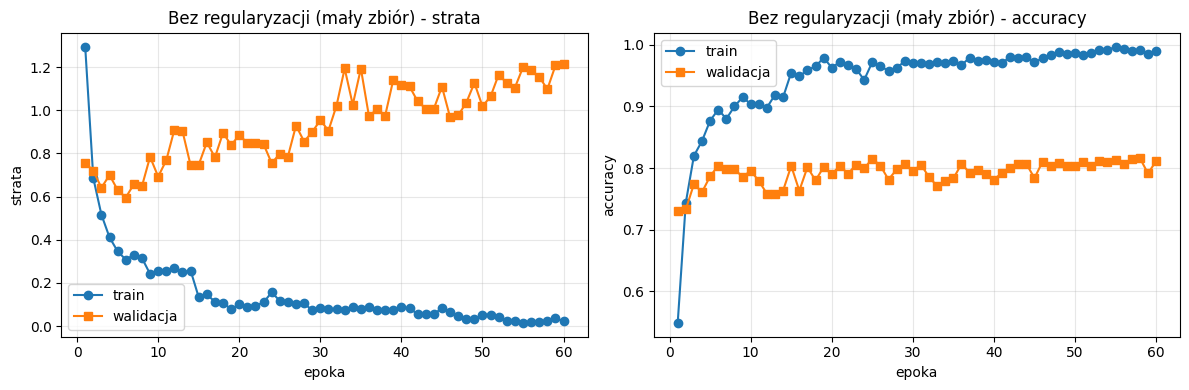

train acc: 0.990, val acc: 0.811, min val_loss w epoce 6


In [21]:
# Mały zbiór treningowy - ułatwia przeuczenie
N_MALY = 500 if SZYBKI_TRYB else 1000
x_maly, y_maly = x_train[:N_MALY], y_train[:N_MALY]
EPOKI_REG = 3 if SZYBKI_TRYB else 60

def zbuduj_przeuczony():
    # Duży MLP bez regularyzacji: 784 -> 512 -> 512 -> 512 -> 10
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten()])
    for _ in range(3):
        model.add(layers.Dense(512, activation="relu"))
    model.add(layers.Dense(10, activation="softmax"))
    return model

def trenuj_reg(model, epoki=EPOKI_REG):
    # Wspólna procedura treningu dla wszystkich wariantów regularyzacji
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model.fit(x_maly, y_maly, epochs=epoki, batch_size=64,
                     validation_data=(x_val, y_val), verbose=0).history

model_over = zbuduj_przeuczony()
print("parametry:", model_over.count_params())
h_over = trenuj_reg(model_over)
rysuj_historie(h_over, tytul="Bez regularyzacji (mały zbiór)")
print(f"train acc: {h_over['accuracy'][-1]:.3f}, val acc: {h_over['val_accuracy'][-1]:.3f}, "
      f"min val_loss w epoce {int(np.argmin(h_over['val_loss'])) + 1}")

### Zadanie 5.1 - Dropout i L2

Napisz funkcję `zbuduj_regularyzowany(dropout=0.0, l2=0.0, batchnorm=False)`, która buduje taką samą architekturę jak `zbuduj_przeuczony`, ale:
- jeśli `l2 > 0`, każda warstwa ukryta `Dense` ma `kernel_regularizer=keras.regularizers.l2(l2)`,
- jeśli `batchnorm=True`, po każdej warstwie `Dense(512)` (bez aktywacji) dodaj `BatchNormalization()`, a następnie `Activation("relu")`,
- jeśli `dropout > 0`, po każdej warstwie ukrytej (po aktywacji) dodaj `Dropout(dropout)`.

Następnie wytrenuj funkcją `trenuj_reg` dwa warianty i zapisz historie:
- `h_drop` - Dropout 0.5,
- `h_l2` - L2 z $\lambda = 10^{-3}$.

**Kryteria sukcesu (pełny tryb):** dla obu wariantów rosnąca część `val_loss` jest wyraźnie mniejsza niż bez regularyzacji, a różnica między train i val accuracy maleje.

**Wskazówki:** pamiętaj o `keras.utils.set_random_seed(SEED)` na początku funkcji (uczciwe porównanie). Kolejność `Dense -> BatchNorm -> ReLU -> Dropout` to popularny wybór; w literaturze spotyka się też BN po aktywacji.

Trenowanie modelu z Dropoutem...


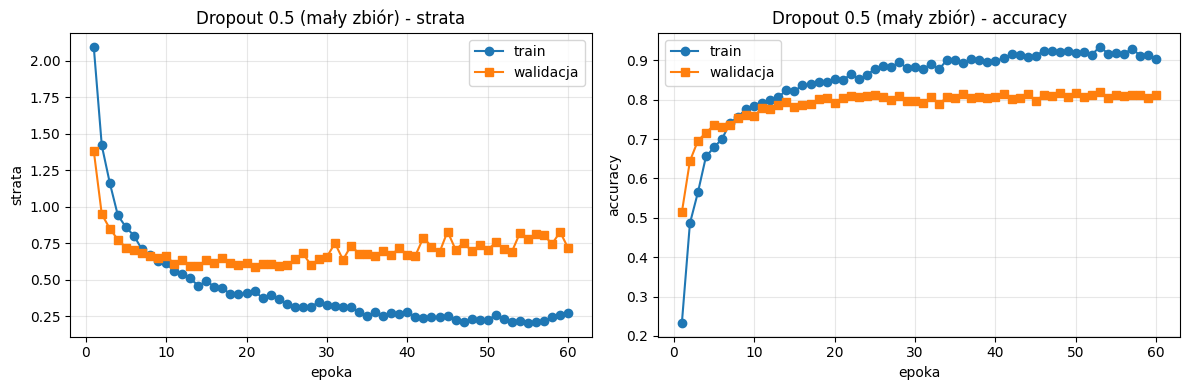

[Dropout] train acc: 0.904, val acc: 0.812

Trenowanie modelu z regularyzacją L2...


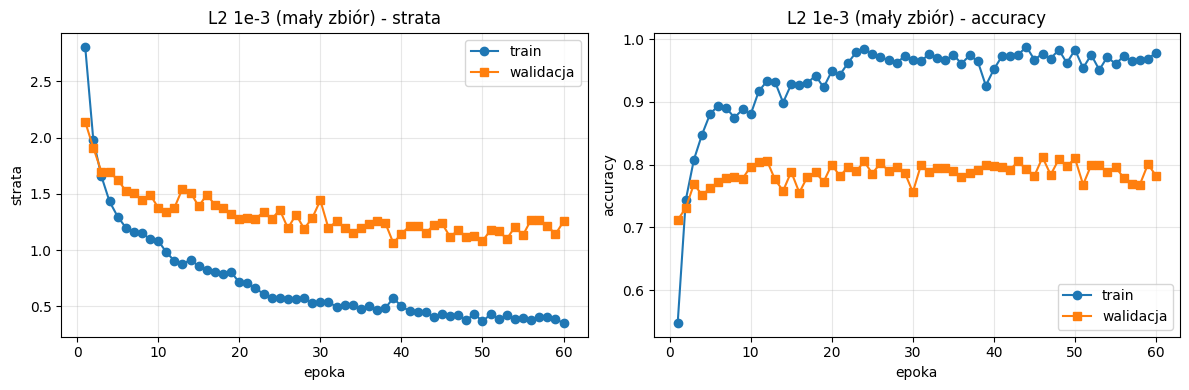

[L2] train acc: 0.978, val acc: 0.782


In [52]:
def zbuduj_regularyzowany(dropout=0.0, l2=0.0, batchnorm=False):
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten()])

    # Dodajemy 3 warstwy ukryte
    for _ in range(3):
        reg_param = keras.regularizers.l2(l2) if l2 > 0 else None

        if batchnorm:
            # Dense -> BatchNorm -> Activation -> Dropout
            model.add(layers.Dense(512, use_bias=False, kernel_regularizer=reg_param))
            model.add(layers.BatchNormalization())
            model.add(layers.Activation("relu"))
        else:
            model.add(layers.Dense(512, activation="relu", kernel_regularizer=reg_param))

        if dropout > 0:
            model.add(layers.Dropout(dropout))

    model.add(layers.Dense(10, activation="softmax"))
    return model

# 1. Trening wariantu z Dropoutem (0.5)
print("Trenowanie modelu z Dropoutem...")
model_drop = zbuduj_regularyzowany(dropout=0.5)
h_drop = trenuj_reg(model_drop)
rysuj_historie(h_drop, tytul="Dropout 0.5 (mały zbiór)")
print(f"[Dropout] train acc: {h_drop['accuracy'][-1]:.3f}, val acc: {h_drop['val_accuracy'][-1]:.3f}")

# 2. Trening wariantu z regularyzacją L2 (1e-3)
print("\nTrenowanie modelu z regularyzacją L2...")
model_l2 = zbuduj_regularyzowany(l2=1e-3)
h_l2 = trenuj_reg(model_l2)
rysuj_historie(h_l2, tytul="L2 1e-3 (mały zbiór)")
print(f"[L2] train acc: {h_l2['accuracy'][-1]:.3f}, val acc: {h_l2['val_accuracy'][-1]:.3f}")

### Zadanie 5.2 - BatchNormalization i zestawienie

1. Wytrenuj wariant z BatchNorm (`h_bn`) oraz wariant łączony BatchNorm + Dropout 0.3 (`h_bn_drop`).
2. Na jednym wykresie narysuj `val_loss` wszystkich pięciu wariantów (bez regularyzacji, Dropout, L2, BN, BN+Dropout).
3. Zbuduj tabelę: najlepsza `val_accuracy`, `val_accuracy` w ostatniej epoce, różnica `accuracy - val_accuracy` w ostatniej epoce (miara przeuczenia).
4. Sformułuj w markdown **hipotezę** przed uruchomieniem (np. "BN poprawi szybkość, ale słabiej ograniczy przeuczenie niż Dropout") i zweryfikuj ją po wynikach (UGŁ_U01).

**Kryteria sukcesu:** tabela i wykres kompletne, hipoteza zweryfikowana wynikami.

*Hipoteza (przed uruchomieniem):*
Batch Normalization ustabilizuje i przyspieszy proces uczenia, pozwalając na stabilniejsze i szybsze schodzenie straty, jednak samo w sobie może słabiej ograniczyć przeuczenie na małym zbiorze danych niż Dropout. Połączenie Batch Normalization i Dropoutu powinno dać najlepszy balans – szybką zbieżność oraz dobrą generalizację (wysoką dokładność walidacyjną i mniejszą lukę generalizacji).

Trenowanie modelu z Batch Normalization...
Trenowanie modelu łączonego (BatchNorm + Dropout 0.3)...


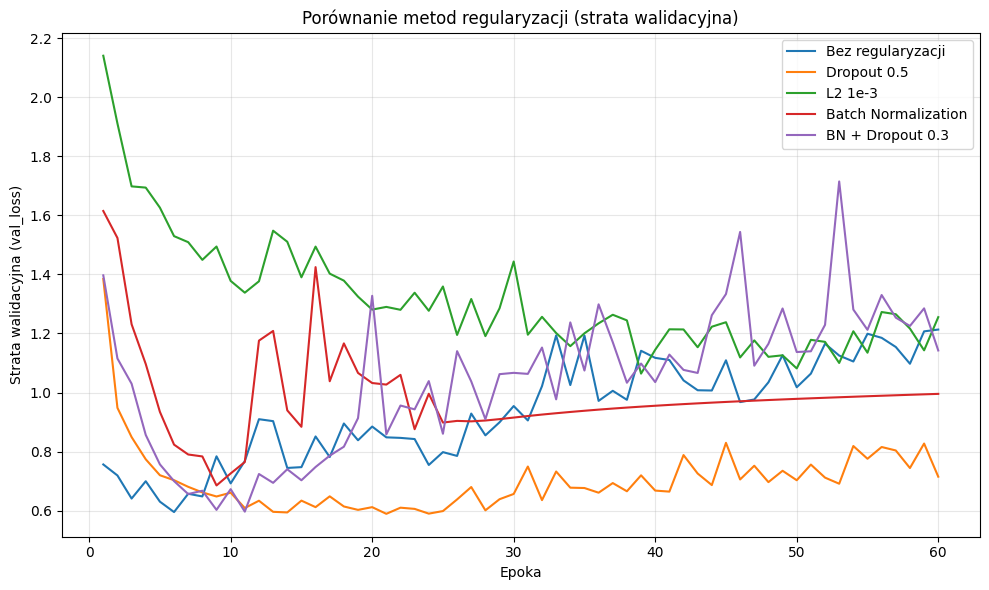


TABELA PORÓWNAWCZA REGULARYZACJI (MAŁY ZBIÓR)
            Wariant  Najlepsze Val Acc  Ostatnie Val Acc  Ostatnie Train Acc  Różnica (Train - Val)
  Bez regularyzacji             0.8164            0.8113               0.990                 0.1787
        Dropout 0.5             0.8191            0.8119               0.904                 0.0921
            L2 1e-3             0.8117            0.7822               0.978                 0.1958
Batch Normalization             0.8136            0.8132               1.000                 0.1868
   BN + Dropout 0.3             0.8105            0.8071               0.990                 0.1829


In [53]:
# Trening wariantu z samą warstwą Batch Normalization
print("Trenowanie modelu z Batch Normalization...")
model_bn = zbuduj_regularyzowany(batchnorm=True)
h_bn = trenuj_reg(model_bn)

# Trening wariantu łączonego: BatchNorm + Dropout (0.3)
print("Trenowanie modelu łączonego (BatchNorm + Dropout 0.3)...")
model_bn_drop = zbuduj_regularyzowany(batchnorm=True, dropout=0.3)
h_bn_drop = trenuj_reg(model_bn_drop)

# Wspólny wykres straty walidacyjnej dla 5 wariantów
plt.figure(figsize=(10, 6))
epoki = np.arange(1, EPOKI_REG + 1)

plt.plot(epoki, h_over["val_loss"], "-", label="Bez regularyzacji")
plt.plot(epoki, h_drop["val_loss"], "-", label="Dropout 0.5")
plt.plot(epoki, h_l2["val_loss"], "-", label="L2 1e-3")
plt.plot(epoki, h_bn["val_loss"], "-", label="Batch Normalization")
plt.plot(epoki, h_bn_drop["val_loss"], "-", label="BN + Dropout 0.3")

plt.xlabel("Epoka")
plt.ylabel("Strata walidacyjna (val_loss)")
plt.title("Porównanie metod regularyzacji (strata walidacyjna)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Budowa tabeli podsumowującej wyniki
historie = {
    "Bez regularyzacji": h_over,
    "Dropout 0.5": h_drop,
    "L2 1e-3": h_l2,
    "Batch Normalization": h_bn,
    "BN + Dropout 0.3": h_bn_drop
}

tabela_wyniki = []
for nazwa, h in historie.items():
    najlepsza_val_acc = np.max(h["val_accuracy"])
    ost_val_acc = h["val_accuracy"][-1]
    ost_train_acc = h["accuracy"][-1]
    roznica = ost_train_acc - ost_val_acc

    tabela_wyniki.append({
        "Wariant": nazwa,
        "Najlepsze Val Acc": najlepsza_val_acc,
        "Ostatnie Val Acc": ost_val_acc,
        "Ostatnie Train Acc": ost_train_acc,
        "Różnica (Train - Val)": roznica
    })

reg_df = pd.DataFrame(tabela_wyniki)
print("TABELA PORÓWNAWCZA REGULARYZACJI (MAŁY ZBIÓR)")
print(reg_df.to_string(index=False))

*Weryfikacja hipotezy:*

1. Batch Normalization (BN) zgodnie z hipotezą bardzo mocno przyspieszył i ustabilizował zbieżność, doprowadzając dokładność treningową do perfekcyjnego poziomu 100% Jednak jako samodzielna metoda słabo ograniczył przeuczenie na tak małym zbiorze – luka generalizacji (różnica `Train - Val) wyniosła aż 0.1868, czyli była zbliżona do wariantu bez regularyzacji 0.1787.
2. Połączenie BN + Dropout 0.3 stabilizuje proces uczenia, ale na tak małym wolumenie danych (1000 próbek) to samodzielny Dropout 0.5 okazał się bezkonkurencyjnym regulatorem. Osiągnął on najniższą lukę generalizacji 0.0921 oraz najwyższą ostateczną i najlepszą dokładność walidacyjną 81.91%.

## 6. Zapis i wczytanie modelu

Wytrenowany model to element cyklu życia systemu (W1, W2): trzeba go zapisać, wersjonować, wczytać w innym procesie (np. serwis predykcyjny). W Keras 3:

| Co | Jak | Zawiera |
|---|---|---|
| pełny model | `model.save("plik.keras")`, `keras.models.load_model("plik.keras")` | architekturę, wagi, konfigurację `compile` i stan optymalizatora |
| tylko wagi | `model.save_weights("plik.weights.h5")`, `model.load_weights(...)` | tylko wartości wag - architekturę trzeba odtworzyć w kodzie |

Format `.keras` to archiwum zip (konfiguracja JSON + wagi). Starszy format `.h5` dla pełnych modeli oraz `SavedModel` są w Keras 3 przestarzałe. **Pamiętaj:** w Colab pliki zapisane na dysku maszyny wirtualnej znikają po zakończeniu sesji - aby je zachować, pobierz je lub zapisz na Google Drive.

Zapis wraz ze stanem optymalizatora pozwala **wznowić trening** dokładnie tam, gdzie go przerwano.

In [24]:
# Demonstracja: zapis i wczytanie pełnego modelu
model_mlp.save("model_mlp.keras")
wczytany = keras.models.load_model("model_mlp.keras")

p1 = model_mlp.predict(x_test[:100], verbose=0)
p2 = wczytany.predict(x_test[:100], verbose=0)
print("Predykcje identyczne:", np.allclose(p1, p2, atol=1e-6))
print("Rozmiar pliku: %.1f kB" % (os.path.getsize("model_mlp.keras") / 1024))
print("Optymalizator wczytanego modelu:", type(wczytany.optimizer).__name__)

Predykcje identyczne: True
Rozmiar pliku: 1215.3 kB
Optymalizator wczytanego modelu: Adam


### Zadanie 6.1 - Zapis wag i wznowienie treningu

1. Zbuduj funkcją `zbuduj_regularyzowany(dropout=0.5)` model, wytrenuj go 2 epoki na `x_maly` (funkcja `trenuj_reg(model, epoki=2)`) i zapisz **same wagi** do `wagi_dropout.weights.h5`.
2. Zbuduj **nowy** model tą samą funkcją, wczytaj do niego wagi i sprawdź (`np.allclose`), że predykcje na `x_test[:100]` są identyczne. Pamiętaj, że Dropout w `predict` jest wyłączony - dlatego wynik jest deterministyczny.
3. Zapisz pierwszy model w całości do `model_dropout.keras`, wczytaj go i **kontynuuj trening** jeszcze 2 epoki przez `fit` (bez ponownego `compile`!). Wypisz `val_accuracy` przed i po.

**Kryteria sukcesu:** oba sprawdzenia `np.allclose` dają `True`; wczytany model trenuje się dalej bez błędu.

**Wskazówka:** nowy model z kroku 2 nie musi być skompilowany, żeby wczytać wagi i wykonać `predict`.

In [55]:
print("--- Krok 1: Budowa modelu i wstępny trening (2 epoki) ---")
model_61 = zbuduj_regularyzowany(dropout=0.5)


model_61.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

hist_init = model_61.fit(x_maly, y_maly, epochs=2, batch_size=64,
                         validation_data=(x_val, y_val), verbose=1)


model_61.save_weights("wagi_dropout.weights.h5")
print("Same wagi zostały zapisane do pliku 'wagi_dropout.weights.h5'.")

# Tworzenie nowego modelu i wczytanie wag
print("\n--- Krok 2: Odtworzenie nowej instancji i wczytanie wag ---")
model_nowy = zbuduj_regularyzowany(dropout=0.5)

# Sprawdzenie predykcji przed wczytaniem wag
pred_przed = model_nowy.predict(x_test[:100], verbose=0)

# Wczytanie zapisanych wag
model_nowy.load_weights("wagi_dropout.weights.h5")
pred_po = model_nowy.predict(x_test[:100], verbose=0)

# Porównanie z predykcjami pierwszego modelu
pred_oryginalne = model_61.predict(x_test[:100], verbose=0)
identyczne = np.allclose(pred_oryginalne, pred_po, atol=1e-6)
print(f"Predykcje nowego modelu po wczytaniu wag są identyczne z oryginalnym: {identyczne}")

# Zapis pełnego modelu i kontynuacja treningu
print("\n--- Krok 3: Zapis pełnego modelu i kontynuacja treningu ---")
# Zapisujemy pierwszy model w całości
model_61.save("model_dropout.keras")
print("Pełny model zapisany jako 'model_dropout.keras'.")

# Wczytujemy pełny model
model_wznowiony = keras.models.load_model("model_dropout.keras")

val_acc_przed = hist_init.history["val_accuracy"][-1]
print(f"Dokładność walidacyjna przed wznowieniem (koniec 2. epoki): {val_acc_przed:.4f}")

# Kontynuujemy trening przez kolejne 2 epoki (bez ponownego compile!)
hist_kontynuacja = model_wznowiony.fit(x_maly, y_maly, epochs=2, batch_size=64,
                                        validation_data=(x_val, y_val), verbose=1)

val_acc_po = hist_kontynuacja.history["val_accuracy"][-1]
print(f"Dokładność walidacyjna po wznowieniu (koniec 4. epoki): {val_acc_po:.4f}")

--- Krok 1: Budowa modelu i wstępny trening (2 epoki) ---
Epoch 1/2
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 189ms/step - accuracy: 0.2330 - loss: 2.0980 - val_accuracy: 0.5144 - val_loss: 1.3843
Epoch 2/2
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.4860 - loss: 1.4199 - val_accuracy: 0.6442 - val_loss: 0.9481
Same wagi zostały zapisane do pliku 'wagi_dropout.weights.h5'.

--- Krok 2: Odtworzenie nowej instancji i wczytanie wag ---
Predykcje nowego modelu po wczytaniu wag są identyczne z oryginalnym: True

--- Krok 3: Zapis pełnego modelu i kontynuacja treningu ---
Pełny model zapisany jako 'model_dropout.keras'.
Dokładność walidacyjna przed wznowieniem (koniec 2. epoki): 0.6442
Epoch 1/2
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 239ms/step - accuracy: 0.5830 - loss: 1.1200 - val_accuracy: 0.6938 - val_loss: 0.8583
Epoch 2/2
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.6510 - loss: 0.9734 - val_accuracy: 0.7042 - val_loss: 0.7735
Dokładność walidacyjna po wznowieniu (koniec 4. epoki): 0.70

## Pytania kontrolne

1. Dlaczego w ostatniej warstwie klasyfikatora na 10 klas używamy softmax, a w regresji warstwy liniowej? Co by się stało, gdyby w regresji cen domów użyć sigmoidy?
2. Czym różni się `sparse_categorical_crossentropy` od `categorical_crossentropy`? Kiedy używamy której?
3. Dlaczego `StandardScaler` dopasowujemy tylko do zbioru treningowego? Jak nazywa się błąd polegający na dopasowaniu go do całych danych i jakie ma skutki?
4. Ile parametrów ma warstwa `Dense(64)` po wejściu o wymiarze 8? A `BatchNormalization` po niej (ile z nich jest uczonych gradientowo)?
5. Co robi `restore_best_weights=True` w `EarlyStopping` i dlaczego jest ważne?
6. Wyjaśnij, czym Adam różni się od zwykłego SGD. Dlaczego SGD bez momentum uczy się wolniej?
7. Na wykresie strata walidacyjna rośnie od 8. epoki, a treningowa dalej spada. Jak to nazywamy i jakie trzy działania podejmiesz?
8. Jak działa Dropout w trakcie treningu, a jak w predykcji? Dlaczego przeskalowuje się aktywacje przez $1/(1-p)$?

1. Dlaczego w ostatniej warstwie klasyfikatora na 10 klas używamy softmax, a w regresji warstwy liniowej? Co by się stało, gdyby w regresji cen domów użyć sigmoidy?
   
Softmax przekształca logity na rozkład prawdopodobieństwa (wartości w przedziale (0, 1), które sumują się do 1), co pozwala określić pewność modelu co do przynależności do danej klasy.
Warstwa liniowa (brak aktywacji) w regresji pozwala modelowi na zwracanie dowolnych liczb rzeczywistych z zakresu $(-\infty, \infty)$ bez sztucznego ograniczania zakresu predykcji.
Gdybyśmy użyli sigmoidy w regresji cen domów, wartości wyjściowe sieci zostałyby ściśnięte do przedziału (0, 1). Ponieważ ceny domów (wyrażone w setkach tysięcy dolarów) są liczbami znacznie większymi (np. 2.5 czy 5.0), model nie byłby w stanie przewidzieć żadnej wartości powyżej 1.0, co doprowadziłoby do całkowitej niefunkcjonalności sieci.

2. Czym różni się `sparse_categorical_crossentropy` od `categorical_crossentropy`? Kiedy używamy której?**
   a)**`sparse_categorical_crossentropy`** jest stosowana, gdy etykiety klas są reprezentowane jako liczby całkowite (np. `0, 1, 2, ..., 9`).

   b) **`categorical_crossentropy`** jest stosowana, gdy etykiety klas są zakodowane metodą one-hot (np. klasa 3 to `[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]`).

   c) Pod względem matematycznym obie funkcje realizują identyczną stratę, lecz wersja `sparse_` jest bardziej efektywna pamięciowo, ponieważ eliminuje potrzebę tworzenia rzadkich macierzy binarnych.

3. **Dlaczego `StandardScaler` dopasowujemy tylko do zbioru treningowego? Jak nazywa się błąd polegający na dopasowaniu go do całych danych i jakie ma skutki?**

Średnią  oraz odchylenie standardowe wyznaczamy wyłącznie na zbiorze treningowym, aby zbiory walidacyjny i testowy pozostały dla modelu całkowicie "nieznane" przed ewaluacją.
Dopasowanie skalera do całego zbioru danych przed podziałem nazywamy wyciekiem danych (data leakage).
Skutkiem tego błędu jest sztuczne zawyżenie wyników ewaluacji (zbyt optymistyczna metryka na zbiorze testowym), ponieważ informacje statystyczne z testu wpłynęły pośrednio na proces przygotowania danych treningowych.

4. **Ile parametrów ma warstwa `Dense(64)` po wejściu o wymiarze 8? A `BatchNormalization` po niej (ile z nich jest uczonych gradientowo)?**

Warstwa `Dense(64)`: Posiada 8 x 64 (wagi) + 64 (biasy) = 576 parametrów .

BatchNormalization` po niej normalizuje 64 kanały aktywacji. Posiada 4 parametry na każdy kanał (średnia, wariancja, współczynnik skalujący oraz przesunięcie). Łącznie daje to 64 x 4 = 256 parametrów.

Parametry uczone gradientowo: Tylko współczynnik skalujący oraz przesunięcie są modyfikowane za pomocą gradientu (64 x 2 = 128 parametrów). Pozostałe 128 parametrów (średnia i wariancja ruchoma) to nienauczane statystyki wyznaczane bezpośrednio z danych.

5. **Co robi `restore_best_weights=True` w `EarlyStopping` i dlaczego jest ważne?**
Po przerwaniu treningu, parametr ten przywraca wagi modelu z epoki, w której monitorowana metryka (np. val_loss) osiągnęła absolutne minimum.
Jest to niezwykle ważne, ponieważ bez tej opcji model zachowałby wagi z ostatniej (często już przeuczonej i gorszej pod kątem generalizacji) epoki treningowej.

6. **Wyjaśnij, czym Adam różni się od zwykłego SGD. Dlaczego SGD bez momentum uczy się wolniej?**

 a) SGD modyfikuje wagi wykonując krok o stałej wielkości w kierunku przeciwnym do gradientu. Bez momentum jest podatny na utknięcie w lokalnych minimach i oscylacje w wąskich dolinach funkcji straty.

b) Adam łączy koncepcję momentum (kumulacja wcześniejszych gradientów ułatwiająca pokonywanie płaskowyżów i minimów) oraz RMSprop (adaptacyjne skalowanie kroku uczenia osobno dla każdego parametru na podstawie średniej kwadratów gradientów).

c) SGD bez momentum uczy się wolniej, ponieważ nie posiada "rozpędu", co zmusza go do wykonywania bardzo małych kroków w silnie zaszumionych kierunkach i spowalnia postęp w obszarach o małym nachyleniu.

7. **Na wykresie strata walidacyjna rośnie od 8. epoki, a treningowa dalej spada. Jak to nazywamy i jakie trzy działania podejmiesz?**

Zjawisko to nazywamy przeuczeniem.
Przykładowe trzy działania zapobiegawcze:
     1. Zastosowanie Early Stopping w celu przerwania treningu w okolicach 8. epoki.
     2. Wprowadzenie warstw Dropout lub regularyzacji L2 (weight decay) w celu ograniczenia pojemności pamięciowej sieci.
     3. Zwiększenie wolumenu danych treningowych (np. poprzez augmentację danych lub pozyskanie nowych próbek).

8. **Jak działa Dropout w trakcie treningu, a jak w predykcji? Dlaczego przeskalowuje się aktywacje przez $1/(1-p)$?**

W trakcie treningu: Z prawdopodobieństwem p losowo zeruje wyjściowe aktywacje neuronów w danej warstwie dla każdego mini-batcha.

W trakcie predykcji (ewaluacji): Jest całkowicie wyłączony – wszystkie neurony pracują deterministycznie.

Skalowanie o 1/(1-p): Wykonywane w trakcie treningu (tzw. Inverted Dropout). Ponieważ podczas uczenia wyłączamy część neuronów, oczekiwana suma sygnału przekazywanego dalej maleje. Przemnożenie pozostałych aktywnych neuronów przez współczynnik $\frac{1}{1-p}$ pozwala zachować tę samą skalę i energię sygnału w fazie treningu i testu bez konieczności modyfikowania wag podczas predykcji.

## Podsumowanie - co warto zapamiętać

- Keras: `Sequential` / `Input` -> `compile(optimizer, loss, metrics)` -> `fit(..., validation_data=...)` -> `evaluate` / `predict`.
- **Klasyfikacja:** wyjście `Dense(K, softmax)` + `sparse_categorical_crossentropy` (etykiety całkowite). **Regresja:** wyjście `Dense(1)` liniowe + MSE (raportuj MAE/RMSE).
- **Normalizuj dane;** parametry skalowania dopasowuj **tylko na train** - inaczej wyciek danych.
- Zawsze porównuj z **baseline'em** (średnia, regresja liniowa) - bez tego nie wiesz, czy sieć cokolwiek daje.
- **Krzywe uczenia** to podstawowe narzędzie diagnostyczne: niedouczenie vs przeuczenie.
- **Callbacki:** `EarlyStopping(restore_best_weights=True)`, `ModelCheckpoint(save_best_only=True)`, `ReduceLROnPlateau`.
- **Learning rate** jest najważniejszym hiperparametrem; Adam (1e-3) to dobry punkt startowy, SGD+momentum - solidna alternatywa.
- **Regularyzacja:** Dropout i L2 zmniejszają lukę train-val; BatchNorm głównie stabilizuje trening; najlepsze lekarstwo to więcej danych.
- Zapis: `.keras` (pełny model, wznowienie treningu) lub `.weights.h5` (same wagi).

## Do sprawozdania końcowego

Z tego laboratorium umieść w sprawozdaniu (zwięźle, maks. 1,5 strony):

1. **Krzywe uczenia** MLP z zad. 1.1 z krótką diagnozą (w której epoce zaczyna się przeuczenie) oraz dokładność testową.
2. **Tabelę regresji** z zad. 2.2 (średnia / regresja liniowa / MLP; MAE i RMSE) i wykres y vs y_pred z komentarzem o obciętych wartościach.
3. **Porównanie optymalizatorów** (zad. 4.1) - wykres i 2-3 zdania interpretacji.
4. **Tabelę regularyzacji** z zad. 5.2 wraz z **hipotezą i jej weryfikacją** (UGŁ_U01).
5. Jedną **propozycję usprawnienia** (UGŁ_U02), np. inny harmonogram lr, AdamW, augmentacja, inna architektura - z uzasadnieniem.

## Zadanie dodatkowe (dla chętnych) - własny callback i harmonogram lr

1. Napisz własny callback `ZatrzymajPrzyDokladnosci(keras.callbacks.Callback)`, który:
   - w `on_epoch_end` zapisuje do listy bieżący learning rate optymalizatora (`float(self.model.optimizer.learning_rate)`),
   - przerywa trening (`self.model.stop_training = True`), gdy `val_accuracy` przekroczy zadany próg (argument konstruktora), i wypisuje komunikat.
2. Wytrenuj MLP 256-128 na Fashion-MNIST z optymalizatorem Adam, którego learning rate jest harmonogramem `keras.optimizers.schedules.CosineDecay(initial_learning_rate=1e-3, decay_steps=...)` (liczba kroków = epoki x liczba batchy na epokę), z progiem 0.89.
3. Narysuj zapisany przez callback przebieg learning rate.

**Wskazówka:** liczba batchy na epokę to `ceil(len(x_train) / batch_size)`.

In [26]:
EPOKI_DOD = 2 if SZYBKI_TRYB else 20

# TODO: uzupełnij - własny callback + CosineDecay